# MAB Price Optimization

## Outline

**Introduction**
* Objectives, methodoloty, tests, and summary of experiment results

**Price Optimization Architecture, Prinnciples and Paramters**
* provides the bases and overview of methods, theory, and parameters 

**Notebook Setup**
* notebook general imports

**Demand Model and Parameters**
* sets demand noise variation 
  
**Revenue Profit Costs**
* calculate revenue, profit and max revenue based on demand parameters

**MAB Experiments**
* Experiment Parameters - set experiment parameters
* Experiment Loop - run N experiments (~100)

**Evaluate MAB Loop Results**
* graphic and text evaluation of experiment results

**Experiment Results Summary**
* Refer to the Introduction and Experiment Results Summary section for more details
* Results summary for various experiments
  * Logit Demand
  * Linear Demand 1
  * Linear Demand 2
  * Constant Elasticity Demand
* Auto Generate experiments summary




# Introduction

### Objective 
*  Price Optimization without assuming demand shape.

### Methodology 
*  MAB (multi-armed bandit) loop with price exploration and regression based demand estimation.
*  Pick among candidate estimation models
*  

### Demand models and Parameters
* Revenue, profit and max revenue based on demand parameters
* p_opt = 2.7
* CV = 0.2
* all demand models configured such that p_opt = 2.7 for maxium profit
  * CV = 0.2, Coefficient of Variation
  * sigma_log = 0.19804220043536505
  * v = 1.8, elasticity
  * c = 1.2, variable costs
  * F = 6, Fixed costs
* sets up the demand models - linear, constant elasticity, and logit

### Revenue Profit Costs
* profit_opt $\approx$ $998


### MAB Experiments
* Experiment Parameters - set experiment parameters
* adjust paramters such as - number of experiments, N_price_repeat, demand models, default model, fallback model, model selection parameters, initial prices ... 

* Three demand types
  * linear demand
  * constant elasticity demand
  * logit demand


* For each experiment loop
  * setup experiment parameters
  * specifiy candidate models - models to fit and select based on selection criteria
  * specificy default model - if linear model curvature tests do not trust more complex models
  * specifify fallback model - in case candidate models violate boundary condition
* Estimation model types
  * linear
  * quadratic
  * log-quadratic-level
  * log_log
  * log_quadratic
  
* Experiment Loop - run N experiments (~100)

### Experiment Results Summary

* Logit Demand
  *  Emulates relistic demand over a broad price range ... 2.00 to 4.00
  *  3 fit models found to be most effective - Linear, quadratic, Log-quadratic-level 
  *  Price exploration consists of 5 price scan from bottom of the price to top of price range and 
  price repeat of 4
  * p_opt_hat_min $\approx$ 2.5
  * p_opt_hat_max $\approx$ 2.92

* Linear Demand 1
    * limited price range: 2.16 to 3.4
    * price exploration is similar to previous experiment, a scan of 5 prices from bottom to top of price range. 
    * N_price_repeat = 4 with a total of 24 observations per experiment
    * N_post_init observations = 1 x N_price_repeat = 4, resulting in 24 observations
    * The post init observations help for compensatating for the occasional boundary violation after the initial low to high price scan.
    *  p_opt_hat_min $\approx$ 2.5
    * p_opt_hat_max $\approx$ 2.92

* Linear Demand 2
    * limited price range: 2.16 to 3.4
    * Price exploration is fixed to two prices at top and bottom of price range
    * A high amount of N_price_repeat = 16 is required achieve enough samples for stable/consistent estimation accuracy
    * This results in 48 observations required (high)
    * It may be possible to narrow the price range for more accuracy but high N_price_repeat is required
    * p_opt_hat_min $\approx$ 2.48
    * p_opt_hat_max $\approx$ 2.96

* Constant Elasticity Demand
    * limited price range: 2.16 to 3.4
    * price exploration is similar to previous experiment, a scan of 5 prices from bottom to top of price range. 
    * N_price_repeat = 4 with a total of 24 observations per experiment (N_post_initial_prices = 1)

    * p_opt_hat_min $\approx$ 2.5
    * p_opt_hat_max $\approx$ 3.0


# Price Optimization Architecture, Principles, and Parameters

### Demand Types

**Constant Elasticity**
* Urealisitc over large price variations, but useful approximation over narrow price regions
* Useful for local approximation, +/- 10 - 20 %, where real demand elasticity can appear constant
* Sometimes groups of products can exhibit constant elasticity, over small price regions
* Esimators struggle to accurately estimate optimum price for large price variations under constant elasticity of demand. Though, estimation over small price regions (+/- 20%) are ok??

**Linear**
* Linear demand is again, like constant elasticity, an approximation, and not a realistic demand function.
* It has two obvious global problems. At sufficiently high prices it predicts negative demand, and at sufficiently low prices it does not naturally represent saturation or a finite population of potential buyers. So, like constant elasticity, we generally shouldn't interpret it as globally valid.
* It is a realistic approximation over a narrow price range. If prices vary only moderately around the economically relevant region, linear demand isn't merely convenient—it is the natural first-order approximation to essentially any smooth demand curve.

**Logit**
* Approximates real world demand behavior
* As price increases price sensitivity increases (elasticity), $\%  \Delta d / \% \Delta p$ and elasticity decreases (price sensitivity) as price falls


**Tips for Estimataion on Demand Types**

* Test constant elasticity over small price region
* Testing of linear demand estimation for for price and profit over a broad region, or small region, produces accurate results.
* Test logit and linear elasticity over larger price regions, small and large price variations, produces reasonably accurate results.

### Demand Estimation Models
Afer extensive testing the following demand models are found to work well as a coordinated set

**linear**  
&emsp; $d = \beta_0 + \beta_1 \, p $

**quadratic**  
&emsp; $ d = \beta_0 + \beta_1 \,  p + \beta_2 p^2$

**log-quadratic-level**  
&emsp;  $\log \, d = \beta_0 + \beta_1 \, p + \beta_2 p^2$

**log-log**   
&emsp;  $\log \, d = \beta_0 + \beta_1 \, \log \, p $  
&emsp;  direct match for constant elasticity with $\beta_1$ = elasticity

quadratic forms $\beta_2$  

* if $\beta_2 \approx 0$, elasiticiay is approximately constant and quadratic forms collapse naturally to a linear form.  
* if $\beta_2$ is meaningfully nonzero, there is evidence then elasticity varies with price. 

log quadratic level level (linear) penalty

this model is not the ordinary LogQL model. It changes the entire coefficient-estimation criterion from log-demand RSS to demand-level RSS.

Selection Process

$$ \boxed{\text{Linear = diagnostic reference}} $$ $$ \boxed{\text{Fallback = default/safety model}} $$ $$ \boxed{\text{Candidates = models allowed to challenge the fallback}} $$

### Selection Model Architcture
* Default: if too much curvature detected (by linear model) then choose default model
* Bourndary: if boundary condition violated then fallback model


```text
                  FIT Models
                       │
       ┌───────────────┼────────────────┐────────────────┐
       │               │                │                |
 candidates      default model     fallback model      linear  (reference check)
       |               |                |                |
       └───────────────┴────────────────┴────────────────┴
                       │
                       ▼
             LINEAR REFERENCE CHECK
                  /             \
               FAIL             PASS
                │                 │
                ▼                 ▼
          default_model      valid candidates
                                  │
                                  ▼
                         calculate/compare
                         selection_score
                                  │
                                  ▼
                         MIN selection_score
                                  │
                                  ▼
                         best_candidate_model
                                  │
                                  |
                                  ▼
                          PROVISIONAL MODEL
                                  │
                                  ▼
                          boundary safeguard
                            /          \
                          FAIL          PASS
                            │              │
                            ▼              ▼
                    fallback_model     keep model
```



### Linear reference Check
Example  
candidate: LQL (log-quadratic-level)
default: quadratic  
fallback: quadratic  
note: linear model is always fit for the linear tilt (curvature) evaluation

The Linear model acts as the gatekeeper for the more flexible LQ (Log-Quadratic-Level) model and Regularized Q (Quadratic) model.
&emsp;  
&emsp; $linear_{rss} < thr_{rss\_max}$  
&emsp;  
&emsp; and  (tilt)
&emsp;  
&emsp; $abs(linear_{rss\_log\_high} - linear_{rss\_log\_low})  < thr_{rss\_diff\_max}$  
&emsp;  
with the current thresholds:  
&emsp;  
&emsp; $ thr_{rss\_max}$ = 2.0   
&emsp; thr_{rss\_diff\_max}$ = 0.75  

If **both conditions pass**, the observed demand relationship is considered sufficiently stable and balanced for non-linear (quadratic and/or log) models to be trusted, subject to its validity and boundary checks.

If **either condition fails**, the algorithm selects the default model (e.g., Regularized Q, quadratic) as the conservative model, default model.

Boundary and validity checks provide a final safeguard against an LQL fit that produces an economically or numerically unreliable optimum. If LQL fails these checks, selection reverts to Regularized Q.



### Candidate Model Selection 
* defaults to rss  ... currently set to default
* currently seleciton criteria is not so rss is the current candidate model selection model
* Note - in addition to candidate model selection there is also default model and fallback model, see diagram above

```text
    if selection_criterion == "rss":
        selection_score = diagnostics["rss"]

    elif selection_criterion == "log_rmse":
        selection_score = diagnostics["log_rmse"]

    elif selection_criterion == "aic":
        selection_score = diagnostics["aic"]

    elif selection_criterion == "aicc":
        selection_score = diagnostics["aicc"]

    elif selection_criterion == "bic":
        selection_score = diagnostics["bic"]
```


### Model Roles wrt logit demand, three models

- **Linear — stable diagnostic reference.**  
  Linear demand has limited flexibility and therefore provides the most stable indication of the underlying price-demand relationship. A tilt adjustment reduces distortion caused by uneven sampling across the price range. The resulting Linear residuals are used to determine whether the data provide sufficiently reliable evidence to trust additional nonlinear curvature.

- **Regularized Quadratic (Q) — conservative nonlinear default.**  
  The Quadratic model captures curvature while applying a `beta2` penalty (`b2_lambda_q = 10`) to prevent excessive curvature. Experimentally, this has been particularly effective at controlling erroneous **low-price optimum estimates**. Q therefore serves as the conservative fallback whenever the more flexible model cannot be trusted.

- **Log-Quadratic-Level (LQL) — flexible nonlinear model.**  
  LQL models `log(D)` as a quadratic function of price and provides additional flexibility in the shape of the demand curve. It has generally performed better in cases where the estimated optimum is toward the **high side**, where Regularized Q can be overly conservative. LQL is therefore preferred when the Linear diagnostics indicate that the additional curvature can be trusted.


### Summary

The three models are designed to work together rather than simply compete on goodness of fit.
*  **Linear provides the stable, tilt-adjusted diagnostic; Regularized Q provides conservative protection against low-side errors; and LQL provides greater accuracy on the high side when its additional flexibility can be trusted.** 
*  The objective is to automatically obtain a robust estimate of the profit-maximizing price from limited and noisy price-demand data without requiring the end user to select or diagnose the appropriate demand model.

### Linear Model Tilt Adjustment (no longer used, keep for posterity)

The Linear model is intended to provide a stable reference for the overall price-demand relationship. However, with limited and noisy observations, a line can have a good overall fit while still being systematically tilted — fitting demand better at one end of the observed price range than at the other.

To guard against this, the Linear model is **de-tilted** during fitting. The observations are divided into price regions, and the average residual error is calculated separately for the **lowest third** and **highest third** of observed prices. The fitting procedure penalizes differences between these two average residuals, encouraging the Linear model to have similar residual error at both ends of the price range.

Conceptually, the fitting objective is:

**good overall fit + small difference between low-price and high-price average residuals**

The strength of this adjustment is controlled by the parameter `tilt_penalty_linear`. A larger value places greater importance on balancing the residuals at the two ends of the price range, while the ordinary residual-error term continues to ensure a good overall fit. Thus, the procedure does not simply force the line to be flat or arbitrarily rotate it; it finds a compromise between overall fit and avoiding systematic low-to-high residual tilt.

The de-tilting is performed by the `_fit_augmented_penalties()` method, which fits the Linear model using an augmented weighted least-squares objective containing the residual-tilt penalty. The `fit_demand_estimator()` method invokes this procedure for the Linear model whenever `tilt_penalty_linear > 0`.

The code measures tilt on the top third and bottom thirds of the curve

&emsp;&emsp;&emsp; Bottom third of prices   Middle third   Top third of prices  
&emsp;&emsp;&emsp;|---------------------|--------------|---------------------|  
&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;    $T_L$   &emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;&emsp;  $T_H$  

After fitting, the remaining tilt is measured as:

&emsp; $T_{error}=\left|T_H-T_L\right|$

where $T_L$ and $T_H$ are the weighted mean residuals in the lowest and highest thirds of the observed price range. A separate tilt-imbalance diagnostic compares their magnitudes:

&emsp;  $I_{\text{tilt}}= \left||T_H|-|T_L|\right|.$

These diagnostics allow us to verify that the Linear reference model is not obtaining a good overall fit at the expense of a systematic error at one end of the price range.

Conceptually:

```text

                Uneven price sampling and RSS 
                        |
                        v
                Ordinary Linear Fit
                        |
                        v
                Fit can tilt toward the
                densely sampled or high error region
                        |
                        v
                Artificial low/high
                residual imbalance
                        |
                        v
                Potential false signal
                of demand curvature

            With the tilt adjustment:

                Uneven price sampling and RSS error
                        |
                        v
                Tilt-Adjusted Linear Fit
                        |
                        v
                More balanced representation
                of low and high price regions
                        |
                        v
                More meaningful RSS diagnostics
                        |
                        v
                Better decision about whether
                nonlinear curvature can be trusted
```


### Linear Tilt Parameters

&emsp; $tilt_{penalty\_linear}$ = 20.0

Controls the strength of the tilt adjustment applied to the Linear model.

A value greater than 1 increases the penalty associated with an imbalanced Linear fit. The current value of `20.0` provides a relatively strong adjustment because the Linear model is being used primarily as a diagnostic reference rather than simply as an unconstrained least-squares prediction model.

The purpose of this parameter is not to make the Linear model itself more flexible. Instead, it prevents uneven sampling or large low-side or high-side errors, across the price range from excessively tilting the Linear fit and contaminating the RSS diagnostics used for subsequent model selection.

&emsp; $linear_{tilt\_imbalance\_max} = 0.08$


When $ |low-price residual - high-price residual | >  linear_{tilt\_imbalance\_max} $ (top third or bottom third) then linear has excessive tilt imbalance, and a non-linear model is not trusted.


The current model-selection process relies primarily on the resulting Linear RSS diagnostics:

&emsp; $thr_{rss_max} = 2.0 $
&emsp; $thr_{rss\_diff\_max} = 0.75$

Therefore, $linear_{tilt\_imbalance_max}$ should be checked against the current implementation before being described as an active model-selection threshold. If it is still used directly by the Linear fitting or validation procedure, it should remain documented as part of the tilt-control mechanism. If it is no longer used, it can be classified as a legacy experimental parameter.

&emsp; $ tilt_{penalty\_log\_quadratic\_level} = 0.0$

No comparable tilt penalty is currently applied to the Log-Quadratic-Level model.

The Linear tilt adjustment has a specific diagnostic purpose: Linear residuals are used to determine whether nonlinear curvature can be trusted. LQL is the flexible candidate being evaluated after that diagnostic gate and therefore does not currently use the same tilt correction.

## Linear RSS Reliability Test

After the tilt-adjusted Linear model is fitted, two residual diagnostics determine whether the observed demand pattern is sufficiently well behaved to trust the more flexible log model.

The first condition is:

&emsp; $linear_{rss} < thr_{rss\_max}$

where:
&emsp; $thr_{rss\_max} = 2.0$

This limits the total log-scale residual error of the Linear model. A large total RSS indicates substantial curvature, irregularity, or noise in the observed demand relationship. Under these conditions, allowing a more flexible model to extrapolate an optimum price has produced less reliable results, so the algorithm remains with the conservative Regularized Quadratic model.

The second condition is:

&emsp; $ abs(  linear_{rss\_log\_high}  - linear_{rss\_log\_low} ) < {thr\_rss\_diff\_max}$

where:

&emsp; $ thr_{rss\_diff\_max} = 0.75$

This measures whether the Linear model is failing very differently in the low-price and high-price portions of the data.

A large low/high RSS difference indicates asymmetric model error and has been associated with unstable curvature estimates and potentially unreliable optimum-price estimates.

The tilt adjustment is important to the interpretation of this diagnostic. By reducing residual asymmetry caused simply by uneven price sampling, it makes the remaining low/high RSS difference more indicative of the underlying shape of the demand relationship rather than the sampling pattern itself.

Thus the Linear model performs two related functions:

1. It provides a stable, low-variance reference demand model.
2. Its tilt-adjusted residual structure provides a diagnostic for determining whether more flexible nonlinear curvature can safely be trusted.



### Simulation and Model-Selection Parameters

#### Price Sampling and Exploration

&emsp; $price\_repeat = 4$

Number of demand observations obtained at each tested price. Repeated observations provide additional information about demand at that price and reduce the effect of random demand noise on the estimated demand curve.

For $N$ independent observations having variance $\sigma^2$, the variance of their mean is:

&emsp; $\mathrm{Var}(D_{\text{mean}}) = \frac{\sigma^2}{N}$

Thus, four independent observations would reduce the variance of their average to approximately one-quarter of the variance of a single observation, and reduce the standard deviation by approximately one-half.

Because:

&emsp; $\text{price\_repeat\_aggregation} = \text{False}$

the current implementation retains the repeated observations individually rather than replacing them with a single averaged observation. The repeats therefore provide greater estimation precision without explicitly averaging the observations before fitting the model.

&emsp; $\text{price\_repeat\_aggregation} = \text{False}$

Determines whether repeated observations at the same price are aggregated before model fitting. $\text{False}$ retains the individual observations.

&emsp; $N_{\text{initial\_prices}} = \mathrm{int}\left(\frac{\text{price\_range}}{\text{price\_delta\_initial}}\right)$

Determines the number of prices explored during the initial learning period. The initial price observations provide the price variation necessary to begin identifying the shape of the demand curve.

&emsp; $N_{\text{post\_init\_prices}} = 4$

Controls the number of additional price observations following the initial exploration period as the algorithm transitions into model-driven pricing.

&emsp; $\text{price\_delta\_initial\_percent} = 0.20$

Sets the initial exploration price step to 20% of the feasible price range. Expressing the initial step as a percentage makes the exploration policy scale with the overall pricing problem.

&emsp; $\text{price\_delta\_initial} = \mathrm{round}\left(\text{price\_delta\_initial\_percent} \cdot \text{price\_range}, 2\right)$

Converts the initial percentage into the actual price increment used during initial exploration.

&emsp; $\text{price\_delta} = 0.10$

Base price movement used during subsequent learn-and-earn iterations.

&emsp; $\text{price\_delta\_plus} = 0.05$

Additional price increment used by the adaptive price movement logic.

&emsp; $\text{boundary\_buffer} = 0.20$

Defines how close an estimated optimum can be to the permitted price boundary before the estimate is treated as potentially unreliable. Optima near a boundary are more likely to be driven by extrapolation or an unstable fitted demand curve.

### Model Reliability and Selection Thresholds
Maximum acceptable total log-scale RSS from the linear model:

&emsp; $\text{thr\_rss\_max} = 2.0$

The linear model acts as a diagnostic reference. If its total residual error becomes too large, the observed price-demand relationship is exhibiting substantial curvature, irregularity, or noise. In this situation, the flexible log model is considered less trustworthy and the algorithm remains with the conservative regularized quadratic model.

&emsp; $\text{thr\_rss\_diff\_max} = 0.75$

Maximum acceptable difference between the linear model's low-price and high-price log RSS:

&emsp; $linear\_rss\_log\_high$
&emsp; $linear\_rss\_log\_low$
&emsp; $thr\_rss\_diff\_max$

A large difference indicates that the linear approximation is failing very differently on the two sides of the observed price range. This asymmetry has been associated with unstable curvature estimates and potentially unreliable optimum-price estimates.

The log-family model is therefore considered eligible only when both conditions hold:

&emsp; $\text{linear\_rss} < \text{thr\_rss\_max}$

and

&emsp; $\left|\text{linear\_rss\_log\_high} - \text{linear\_rss\_log\_low}\right|< \text{thr\_rss\_diff\_max}$

If either condition fails, the algorithm remains with the regularized quadratic model.

### Legacy / Experimental Parameters

The following parameters were used during earlier development of the model-selection process:

&emsp;$\text{ridge\_cv} = \text{True}$

&emsp; $\text{linear\_rss\_guard\_max} = 3.0$

&emsp; $\text{tilt\_penalty\_linear} = 20.0$

&emsp; $\text{tilt\_penalty\_log\_quadratic\_level} = 0.0$

&emsp; $\text{logq\_aic\_improvement\_min} = 2.0$

The current selection process is primarily driven by:

&emsp; $\text{thr\_rss\_max} = 2.0$

and

&emsp; $\text{thr\_rss\_diff\_max} = 0.75$

together with model AIC, model-validity checks, boundary checks, and the regularized quadratic model as the conservative default.

The low/high residual diagnostic is evaluated as:

&emsp; $\left|\text{linear\_rss\_log\_high} - \text{linear\_rss\_log\_low}\right| < \text{thr\_rss\_diff\_max}$

These older parameters should therefore be reviewed against the current implementation. If they are no longer active in the selection path, they can eventually be removed from both the code and documentation to keep the final algorithm easier to interpret.

# Notebook Setup

In [1]:
!python --version

Python 3.12.7


In [2]:
import sys
from pathlib import Path
sys.path.append(str(Path("..") / "py_modules"))

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import beautifulplots as bp


from demand_elasticity_profit import (
    demand_constant_elasticity, 
    demand_linear, elasticity_linear,
    demand_logit, elasticity_logit,
    get_vhat_invumar_df,
)

from utils_probability import demand_sample

# Demand Models and Parameters

### Demand Parameters

Business Parameters

These parameters are contexttual to the business problem and are necessary to model demand behavior.
* CV - coefficient of variation. Represents the demand variation relative to the mean, $CV = \sigma/\mu$
* c - cost per unit.
* F - fixed cost.

Below (code cell), we use the term `sigma_log` because the standard deviation corresponds to the log domain corresponding to log D demand variations - additive in the log domain (log scale) and multiplicative in the linear domain  (.e., demand with multiplicative "noisy" variation). This is the typical representation for market demand situations. This $sigma_log$ is often simply termed $\sigma$ in the literature, however both represent stadnard-deviation in the log domain.

In [3]:
# Demand General Parameters
CV =0.2 
v = 1.8
c = 1.2
F = 6
sigma_log = np.sqrt(np.log1p(CV**2)) # sqrt(1 + CV^2)

print(f'CV = {CV}, Coefficient of Variation')
print(f'sigma_log = {sigma_log}')
print(f'v = {1.8}, elasticity')
print(f'c = {c}, variable costs')
print(f'F = {F}, Fixed costs')


CV = 0.2, Coefficient of Variation
sigma_log = 0.19804220043536505
v = 1.8, elasticity
c = 1.2, variable costs
F = 6, Fixed costs


Additonal price parameters
*  p0, is the currently set market price, though it is not optimal.
*  price_min - minimum price guard rail
*  price_max - maximum price guard rail

For exemplary purposes, we set the following objectives across the demand functions
1. Profit optimizing price, p_opt, is the same across all the demand functions 
2. Demand, d(p_opt) is the same for all three demand examples.
3. Elasticity at p_opt, is the same for all demand examples.

Demand parameters for the three demand functions - constant elasticity, linear demand, logit demand

We begin with constant elasticity, because it provides conceptual understanding of elasticity. Then, we will set the parameters for the other demand functions to aligned with the profit optimizing price, p_opt, and corresponding elasticity.

In [4]:
# Demand Parameters

#### Constant Elasticity Demand ###
v = 1.8
p_opt = (v / (v - 1)) * c
A_ce = 4000
D_opt = A_ce * p_opt **(-v)
Profit_opt = p_opt * D_opt - c * D_opt - F  

#### linear demand ####
#  - match the slope of the constant elasticity demand at p_opt
#  d_linear = A ( 1 - bp )
#  p_zero = A / b
#  d_linear(p_opt) = d_ce(p_opt)
#  A (1 - b * p_opt) = A * p_opt **(-v)
#  A is known, solve for b
b_linear = v / (( 1 + v) * p_opt)
A_linear = D_opt / (1 - b_linear * p_opt) # A = d(p_opt) / (1 - b * p_opt)

###### Logit #######
# need to solve for a and b
# constraints:
#  1) v_logit(p_opt) =  v = 1.8
#  2) pmid = p_opt
#  b_logit = 2 * v / p_opt ... 
#  a_logit = b_logit * p_opt ... sets the midpoint for logit demand
b_logit =  2 * v / p_opt
a_logit =  b_logit * p_opt
A_logit = 2 * D_opt # Logit demand is A/2 at p_opt

# Constant Elasticity Demand
print('Connstant Elasticity Demand')
print(f'  p_opt = {p_opt}')
print(f'  D_opt = {D_opt}')
print(f'  v = {v}')
print(f'  A_ce = {A_ce}')
print(f'  Profit_opt = {Profit_opt}')

# Linear Demand
print()
print('Linear Demand')
print(f'  A_linear = {A_linear}')
print(f'  b_linear = {b_linear}')

# Logit De`mand
print()
print("Logit Demand")
print(f'  A_logit = {A_logit}')
print(f'  b_logit = {b_logit}')
print(f'  a_logit = {a_logit}')


Connstant Elasticity Demand
  p_opt = 2.6999999999999997
  D_opt = 669.2759448378242
  v = 1.8
  A_ce = 4000
  Profit_opt = 997.9139172567361

Linear Demand
  A_linear = 1873.972645545908
  b_linear = 0.23809523809523814

Logit Demand
  A_logit = 1338.5518896756485
  b_logit = 1.3333333333333335
  a_logit = 3.6


# Revenue Profit Costs

In [5]:
Profit_opt = (p_opt -c) * D_opt -  F

R_opt = p_opt * D_opt

MC = c # marginal cost

TC_p_opt = c * D_opt + F
TCPU_p_opt = TC_p_opt / D_opt

RPU_D_opt = R_opt / D_opt
Profit_opt

print(f'Profit_opt = {Profit_opt}')

Profit_opt = 997.9139172567362


# MAB Loop - Optimum Demand, Price, Profit

mab_experiments results_dict form

```text
results_dict
│
├── observed MAB path
│   ├── p_history
│   ├── d_history
│   └── d_sigma0_history
│
├── selected-model path
│   ├── selected_model              ← selected model at each iteration
│   ├── p_opt_hat_history
│   ├── d_opt_hat_history
│   └── p_opt_hat_error_history
│
├── final selected model
│   ├── selected_model_type
│   ├── dhat_model                  ← selected model prediction function
│   └── model_info                  ← selected model fit information
│
├── model_diagnostics               ← ALL final model diagnostics
│   │
│   ├── linear
│   │   ├── aic
│   │   ├── p_opt_hat
│   │   ├── d_opt_hat
│   │   ├── profit_opt_hat
│   │   ├── tilt_error
│   │   └── ...                     ← other linear diagnostics
│   │
│   ├── log_log
│   │   ├── aic
│   │   ├── p_opt_hat
│   │   ├── d_opt_hat
│   │   ├── profit_opt_hat
│   │   ├── tilt_error
│   │   └── ...                     ← other log-log diagnostics
│   │
│   └── log_quadratic
│       ├── aic
│       ├── p_opt_hat
│       ├── d_opt_hat
│       ├── profit_opt_hat
│       ├── tilt_error
│       ├── beta1
│       ├── beta2
│       └── ...                     ← other log-quadratic diagnostics
│
├── fitted_models                   ← ALL final fitted models
│   │
│   ├── linear
│   │   ├── dhat_model
│   │   └── model_info
│   │
│   ├── log_log
│   │   ├── dhat_model
│   │   └── model_info
│   │
│   └── log_quadratic
│       ├── dhat_model
│       └── model_info
│
├── model_diagnostics_history       ← model_diagnostics at EACH iteration
│   ├── iteration 0
│   ├── iteration 1
│   ├── ...
│   └── final iteration
│
└── fitted_models_history           ← fitted_models at EACH iteration
    ├── iteration 0
    ├── iteration 1
    ├── ...
    └── final iteration
```

### MAB Loop

In [6]:
from demand_price_estimation import mab_price_optimization_loop, get_demand

pd.set_option('display.max_columns', None) # show all columns
pd.set_option('display.max_rows', None) # show all rows

### Loop Parameters

In [138]:
# Loop Parameters

# Demand model and Fit Models 
#demand_type = "constant_elasticity"
demand_type = "linear1"
#demand_type = "linear2"
#demand_type = "logit"
sigma_lg = sigma_log
#sigma_lg = 0.05
#sigma_lg = 0


    
#------------ if Logit ------------
if demand_type == "logit":
    candidate_model_types = [
    "log_quadratic_level",
    ]
    
    default_model_type= "linear"
    fallback_model_type = "linear" 

    p0 = 3.6
    price_min = 2
    price_max = 4.0
    price_range = price_max - price_min # wide range 
    #price_delta_initial_percent = 0.2  # price delta limited to x %
    N_initial_prices = 5 # need at least 5 prices for a consistency
    #price_delta_initial = (price_max - price_min) / (N_initial_prices - 1)
    price_delta = 0.10
    
    # tile penalties
    tilt_penalty_linear = 0 # 20 linear tilt penalty, 1.0 is default, 0.0 is no penalty > 1 (e.g., 4)
    tilt_penalty_log_log = 0 # 10 log-log tilt penalty, 1.0 is default, 0.0 is no penalty > 1 (e.g., 4)
    tilt_penalty_log_level = 0.0 # 10.0 log-level tilt penalty 
    tilt_penalty_log_quadratic = 0.0 #0.0, 5.0 # log-quadratic tilt penalty, 1.0 is default, 0.0 is no penalty > 1 (e.g., 4)
    tilt_penalty_log_quadratic_level = 0.0
    
    N_price_repeat = 4
    N_post_init_prices = 0 # price repeat applies to these post-initial prices
    
    initial_prices = None
    initial_demand = None
    
#------------ Linear 1 ------------    
if demand_type == "linear1":
    demand_type = "linear" # demand_type must match the actual demand model
    candidate_model_types = [
    #"linear",
    #"log_log",
    #"log_quadratic_level",
    "quadratic",
    ]

    default_model_type= "quadratic"
    fallback_model_type = "quadratic"
    
    price_max= round(p_opt + p_opt * 0.2 , 2)  # need some +/- 20 % for estimate consistency
    price_min = round(p_opt - p_opt * 0.2, 2)
    p0 = price_max
    price_range = price_max - price_min
    price_delta_initial_percent = 0.2  # price delta limited to x %
   
    price_delta = 0.10 # after initial prices
    
    # tile penalties
    tilt_penalty_linear = 0.0 # 20 linear tilt penalty, 1.0 is default, 0.0 is no penalty > 1 (e.g., 4)
    tilt_penalty_log_log = 0.0 # 5 log-log tilt penalty, 1.0 is default, 0.0 is no penalty > 1 (e.g., 4)
    tilt_penalty_log_level = 0.0 # log-level tilt penalty 
    tilt_penalty_log_quadratic = 0.0 #0.0, 5.0 # log-quadratic tilt penalty, 1.0 is default, 0.0 is no penalty > 1 (e.g., 4)
    tilt_penalty_log_quadratic_level = 0.0
    
    N_price_repeat = 4
    initial_prices = None
    N_initial_prices = 5 # ... ignored if initial_prices are provided ... scan through price range
    N_post_init_prices = 1 # price repeat applies to post-initial prices
    
#------------ Linear 2 ------------    
if demand_type == "linear2":
    
    demand_type = "linear" # demand_type must match the actual demand model
    candidate_model_types = [
    #"linear",
    #"log_log",
    #"log_quadratic_level",
    "linear",
    ]

    default_model_type= "linear"
    fallback_model_type = "linear"
    
    price_max= round(p_opt + p_opt * 0.2 , 2)  # need some +/- 20 % for estimate consistency
    price_min = round(p_opt - p_opt * 0.2, 2)
    p0 = price_max
    price_range = price_max - price_min
    price_delta_initial_percent = 0.2  # price delta limited to x %
   
    price_delta = 0.10 # after initial prices
    
    # tile penalties
    tilt_penalty_linear = 0.0 # 20 linear tilt penalty, 1.0 is default, 0.0 is no penalty > 1 (e.g., 4)
    tilt_penalty_log_log = 0.0 # 5 log-log tilt penalty, 1.0 is default, 0.0 is no penalty > 1 (e.g., 4)
    tilt_penalty_log_level = 0.0 # log-level tilt penalty 
    tilt_penalty_log_quadratic = 0.0 #0.0, 5.0 # log-quadratic tilt penalty, 1.0 is default, 0.0 is no penalty > 1 (e.g., 4)
    tilt_penalty_log_quadratic_level = 0.0
   
    # --- these for the case of explicitly setting initial prices ------
    N_price_repeat = 16 # 16 REPEATS x 2 + 1  (POST-INITIAL PRICE) x 16
    initial_prices = N_price_repeat * [ 3.0] + N_price_repeat * [  2.4 ] # P
    
    
    N_initial_prices = 5 # ... ignored if initial_prices when initi_prices not None
    N_post_init_prices = 1 # price repeat applies to these post-initial prices
    
#------------ Constant Elasticity  ------------    
if demand_type == "constant_elasticity":
    candidate_model_types = [
    #"linear",
    #"quadratic",
    "log_quadratic_level",
    #"log_quadratic",
    "log_log",
    ]
    fallback_model_type = "quadratic"
    default_model_type= "quadratic"
    price_max= round(p_opt + p_opt * 0.2, 2)
    price_min = round(p_opt - p_opt * 0.2 ,2)
    p0 = price_max
    price_range = price_max - price_min

    price_delta = 0.10 # after initial prices
    
    # tile penalties
    tilt_penalty_linear = 0.0 # 20 or 0 ?linear tilt penalty, 1.0 is default, 0.0 is no penalty > 1 (e.g., 4)
    tilt_penalty_log_log = 0.0 # 5 log-log tilt penalty, 1.0 is default, 0.0 is no penalty > 1 (e.g., 4)
    tilt_penalty_log_level = 0.0 # log-level tilt penalty 
    tilt_penalty_log_quadratic = 0.0 #0.0, 5.0 # log-quadratic tilt penalty, 1.0 is default, 0.0 is no penalty > 1 (e.g., 4)
    tilt_penalty_log_quadratic_level = 0.0
    
    N_price_repeat = 4 # see minor, if any, improvement when increase this to 8 or 16
    N_initial_prices = 5 #  ignored if initial_prices are provid`ed
    N_post_init_prices = 1 # price repeat applies to these post-initial prices
    initial_prices = None
    initial_demand = None
    

if initial_prices:
    N_loop = len(initial_prices) +  N_post_init_prices * N_price_repeat 
else:
    N_loop = N_price_repeat * N_initial_prices + N_post_init_prices * N_price_repeat 
    
demand_params = {}
if demand_type == "constant_elasticity":
    demand_params = {"A": A_ce, "v": v, }

elif demand_type == "linear":
    demand_params = { "A": A_linear, "b": b_linear  }

elif demand_type == "logit":
    demand_params = {  "A": A_logit,"a": a_logit, "b": b_logit,}
ridge_cv_linear = False
ridge_cv_q = False
ridge_cv_lql = True # regularized log-quadratic-level model
b2_lambda_q = 10.0
b2_lambda_lql = 0.0
b2_lambda_lql_lp = 0.0
thr_rss_diff_max = .75
thr_rss_max = 2.0
# logq_aic_improvement_min=2.0 ... deprecated, logic not implemented

N_experiments = 100
price_delta_plus = 0.05  # depracted for local window
price_local_window = False # depraccated

price_repeat_aggregation = False
boundary_buffer = .2
huber = False
# ridge_cv = True # ... depracated 
linear_rss_guard_max = 3.0

# Models fitted includes candidate, default and fallback models, plus linear model as reference for diagnostics
models_to_fit = list(dict.fromkeys(candidate_model_types + [ "linear", default_model_type,  fallback_model_type,]  ))

print(f"demand_type = {demand_type}")
print(f"candidate_model_types = {candidate_model_types}")
print(f'default_model_type = {default_model_type}')
print(f'fallback_model_type = {fallback_model_type}')
print(f'N_experiments = {N_experiments}')
print(f'Nloop = {N_loop}')
print(f'Nprice_repeat = {N_price_repeat}')
print(f'price_repeat_aggregation = {price_repeat_aggregation}')
print(f'N_initial_prices = {N_initial_prices}')
print(f'N_post_init_prices = {N_post_init_prices}')
print(f'boundary_buffer = {boundary_buffer}')
print(f"sigma_lg = {sigma_lg}")
print(f"demand_params = {demand_params}")
# print(f'ridge_cv = {ridge_cv}')
print(f"thr_rss_max = {thr_rss_max}")
print(f"thr_rss_diff_max = {thr_rss_diff_max}")
print(f"b2_lambda_q = {b2_lambda_q}")
print(f"b2_lambda_lql = {b2_lambda_lql}")
print(f"b2_lambda_lql_lp = {b2_lambda_lql_lp}")
print(f"models_to_fit = {models_to_fit}")
print(f"tilt_penalty_linear = {tilt_penalty_linear}")
print(f'tilt_penalty_log_level = {tilt_penalty_log_level}')
print(f"tilt_penalty_log_log = {tilt_penalty_log_log}")
print(f"tilt_penalty_log_quadratic = {tilt_penalty_log_quadratic}")
print(f"tilt_penalty_log_quadratic_level = {tilt_penalty_log_quadratic_level}")
print(f'price_delta = {price_delta}')
print(f'price_delta_plus = {price_delta_plus}')
print(f'price_local_window = {price_local_window}')
print(f"initial_prices = {initial_prices}")

demand_type = linear
candidate_model_types = ['quadratic']
default_model_type = quadratic
fallback_model_type = quadratic
N_experiments = 100
Nloop = 24
Nprice_repeat = 4
price_repeat_aggregation = False
N_initial_prices = 5
N_post_init_prices = 1
boundary_buffer = 0.2
sigma_lg = 0.19804220043536505
demand_params = {'A': 1873.972645545908, 'b': 0.23809523809523814}
thr_rss_max = 2.0
thr_rss_diff_max = 0.75
b2_lambda_q = 10.0
b2_lambda_lql = 0.0
b2_lambda_lql_lp = 0.0
models_to_fit = ['quadratic', 'linear']
tilt_penalty_linear = 0.0
tilt_penalty_log_level = 0.0
tilt_penalty_log_log = 0.0
tilt_penalty_log_quadratic = 0.0
tilt_penalty_log_quadratic_level = 0.0
price_delta = 0.1
price_delta_plus = 0.05
price_local_window = False
initial_prices = None


### MAB Experiment Loop

In [141]:
# ========== MAB Experiment Loop ========================#
# note sometimes can get WARNING that p_opt_hat is outside the price range
#  but then the resutls show price inside the range 
#  the inside price range can be a CORRECTION after the initial prices

verbose = 0

# ----------- print experiment parameters -----------
print(f"demand_type = {demand_type}")
print(f"N_experiments = {N_experiments}")
print(f"Nloop = {N_loop}, total MAB observations")
if initial_prices:
    print(f"N_learn_earn = {N_loop - len(initial_prices)}, Learn and Earn observations")
print(f"sigma_lg = {sigma_lg}")
print(f'p0 = {p0}, initial price')
print(f'price_min = {price_min}, minimum price')
print(f'price_max = {price_max}, maximum price')
print(f"Nprice_repeat = {N_price_repeat}")
print(f'price_repeat_aggregation = {price_repeat_aggregation}')
print(f"N_initial_prices = {N_initial_prices}")
print(f'N_post_init_prices = {N_post_init_prices}')
print(f"candidate_model_types = {candidate_model_types}")
print(f'default_model_type = {default_model_type}')
print(f'fallback_model_type = {fallback_model_type}')
print(f"models_to_fit = {models_to_fit}")
print(f"ridge_cv_linear = {ridge_cv_linear}")
print(f"ridge_cv_q = {ridge_cv_q}")
print(f"ridge_cv_lql = {ridge_cv_lql}")
print(f"huber = {huber}")
print(f"thr_rss_max = {thr_rss_max}")
print(f"thr_rss_diff_max = {thr_rss_diff_max}")
print(f"b2_lambda_q = {b2_lambda_q}")
print(f"b2_lambda_lql = {b2_lambda_lql}")
print(f"b2_lambda_lql_lp = {b2_lambda_lql_lp}")
print(f"tilt_penalty_linear = {tilt_penalty_linear}")
print(f"tilt_penalty_log_log = {tilt_penalty_log_log}")
print(f"tilt_penalty_log_quadratic = {tilt_penalty_log_quadratic}")
print(f"tilt_penalty_log_quadratic_level = {tilt_penalty_log_quadratic_level}")
print(f'price_delta = {price_delta}')
print(f'price_delta_plus = {price_delta_plus}')
print(f'price_local_window = {price_local_window}')
print(f"initial_prices = {initial_prices}")

# ---------------- experiment histories ----------------

k_history = []
demand_type_history = []
selected_model_history = []

p_opt_hat_history = []
p_opt_hat_error_history = []
d_opt_hat_history = []
sigma_log_history = []

results_dict_list = []

# ---------------- model diagnostics histories ----------------

# p_opt_hat histories
linear_p_opt_hat_history = []
quadratic_p_opt_hat_history = []
log_log_p_opt_hat_history = []
log_quadratic_p_opt_hat_history = []
log_quadratic_level_p_opt_hat_history = []
log_quadratic_level_lp_p_opt_hat_history = []

# Model Selection Diagnostics
p_opt_linear_delta_frac_history = []

# aic histories
linear_aic_history = []
quadratic_aic_history = []
log_log_aic_history = []
log_quadratic_aic_history = []

# rss (residual sum of squares) histories
# log-demand RSS
linear_rss_history = []
quadratic_rss_history = []
log_log_rss_history = []
log_quadratic_rss_history = []
log_quadratic_level_rss_history = []
log_quadratic_level_lp_rss_history = []

# demand-level RSS
linear_rss_level_history = []
quadratic_rss_level_history = []
log_log_rss_level_history = []
log_quadratic_rss_level_history = []
log_quadratic_level_rss_level_history = []
log_quadratic_level_lp_rss_level_history = []

log_quadratic_level_selected_alpha_history = []

# ---------- Regional RSS histories ----------#

# linear
linear_rss_log_low_history = []
linear_rss_log_high_history = []
linear_rss_level_low_history = []
linear_rss_level_high_history = []

# quadratic
quadratic_rss_log_low_history = []
quadratic_rss_log_high_history = []
quadratic_rss_level_low_history = []
quadratic_rss_level_high_history = []

# log-log
log_log_rss_log_low_history = []
log_log_rss_log_high_history = []
log_log_rss_level_low_history = []
log_log_rss_level_high_history = []

# log-quadratic
log_quadratic_rss_log_low_history = []
log_quadratic_rss_log_high_history = []
log_quadratic_rss_level_low_history = []
log_quadratic_rss_level_high_history = []

# log-quadratic-level
log_quadratic_level_rss_log_low_history = []
log_quadratic_level_rss_log_high_history = []
log_quadratic_level_rss_level_low_history = []
log_quadratic_level_rss_level_high_history = []

# log-quadratic-level LP
log_quadratic_level_lp_rss_log_low_history = []
log_quadratic_level_lp_rss_log_high_history = []
log_quadratic_level_lp_rss_level_low_history = []
log_quadratic_level_lp_rss_level_high_history = []

# beta histories, aic, linear delta frac
log_quad_beta1_history = []
log_quad_beta2_history = []
log_quadratic_level_lp_beta2_history = []
logq_vs_loglog_aic_improvement_history = []

# tilt diagnostics histories 

tilt_error_linear_history = []
tilt_error_linear_low_history = []
tilt_error_linear_high_history = []
tilt_imbalance_linear_history = []

tilt_error_log_log_history = []
tilt_error_log_log_low_history = []
tilt_error_log_log_high_history = []

tilt_error_log_quadratic_history = []
tilt_error_log_quadratic_low_history = []
tilt_error_log_quadratic_high_history = []

quadratic_beta1_history = []
quadratic_beta2_history = []

quadratic_vhat_at_linear_p_opt_history = []
quadratic_vhat_delta_from_linear_history = []

ql_1prime_history = []
ql_2prime_history = []
ql_dvhat_dp_history = []
ql_d2d_over_d_history = []
ql_d2d_over_dd_history = []

# log-quadratic-level diagnostics histories 
log_quadratic_level_beta2_history = []

log_quadratic_level_lp_vhat_at_linear_p_opt_history = []
log_quadratic_level_lp_vhat_delta_from_linear_history = []

# LogQL-LP curvature diagnostics
logql_lp_1prime_history = []
logql_lp_2prime_history = []
logql_lp_dvhat_dp_history = []
logql_lp_d2d_over_d_history = []
logql_lp_d2d_over_dd_history = []

# ---------------- nonlinear model diagnostics histories ----------------

linear_vhat_at_linear_p_opt_history = []
log_log_vhat_at_linear_p_opt_history = []
log_quadratic_vhat_at_linear_p_opt_history = []
log_quadratic_level_vhat_at_linear_p_opt_history = []

log_log_vhat_delta_from_linear_history = []
log_quadratic_vhat_delta_from_linear_history = []
log_quadratic_level_vhat_delta_from_linear_history = []

# LogQ curvature diagnostics
logq_1prime_history = []
logq_2prime_history = []
logq_dvhat_dp_history = []
logq_d2d_over_d_history = []
logq_d2d_over_dd_history = []

# LogQL curvature diagnostics
logql_1prime_history = []
logql_2prime_history = []
logql_dvhat_dp_history = []
logql_d2d_over_d_history = []
logql_d2d_over_dd_history = []

# ============= Experiments Loop ===================#

for k in range(N_experiments):

    print("k = ", k, end=", ")
    
    if initial_prices:
        initial_demand = np.round( get_demand(demand_type,demand_params,initial_prices, sigma_log=sigma_log), 1)
        #print(f"initial_demand = {initial_demand}")
        if verbose > 0:
            print(f"initial_prices = {initial_prices}")
            print(f"initial_demand = {initial_demand}")
    else:
        initial_demand = None

    results_dict =  mab_price_optimization_loop(
        price_min,
        price_max,
        c,
        F,
        p_opt,
        demand_type,
        demand_params,
        sigma_lg,
        N_loop=N_loop,
        N_price_repeat=N_price_repeat,
        price_repeat_aggregation=price_repeat_aggregation,
        candidate_model_types=candidate_model_types,
        default_model_type=default_model_type,
        fallback_model_type=fallback_model_type,
        ridge_cv_linear=ridge_cv_linear,
        ridge_cv_q=ridge_cv_q,
        ridge_cv_lql=ridge_cv_lql,
        huber=huber,
        b2_lambda_q=b2_lambda_q,
        b2_lambda_lql=b2_lambda_lql,
        b2_lambda_lql_lp=b2_lambda_lql_lp,
        price_delta=price_delta,
        price_delta_plus=price_delta_plus,
        price_local_window=price_local_window,
        initial_prices=initial_prices,
        initial_demand=initial_demand,
        boundary_buffer=boundary_buffer,
        N_initial_prices=N_initial_prices,
        tilt_penalty_linear=tilt_penalty_linear,
        tilt_penalty_log_level=tilt_penalty_log_level,
        tilt_penalty_log_log=tilt_penalty_log_log,
        tilt_penalty_log_quadratic=tilt_penalty_log_quadratic,
        tilt_penalty_log_quadratic_level=tilt_penalty_log_quadratic_level,
        thr_rss_max=thr_rss_max,
        thr_rss_diff_max=thr_rss_diff_max,
        verbose=verbose,
    )

    results_dict_list.append(results_dict)


    # ---------- Final results from experiment ----------#

    selected_model_k = results_dict["selected_model_type"]
    p_opt_hat_k = results_dict["p_opt_hat_history"][-1]
    d_opt_hat_k = results_dict["d_opt_hat_history"][-1]

    # Final diagnostics and fitted models for all candidates
    model_diagnostics_k = results_dict["model_diagnostics"]
    fitted_models_k = results_dict["fitted_models"]


    # ---------- Store experiment results ----------#

    k_history.append(k)
    demand_type_history.append(demand_type)
    selected_model_history.append(selected_model_k)

    p_opt_hat_history.append(p_opt_hat_k)

    p_opt_hat_error_history.append(
        abs(p_opt_hat_k - p_opt)
    )

    d_opt_hat_history.append(d_opt_hat_k)
    sigma_log_history.append(sigma_lg)

    # ---------- Model-selection diagnostics ----------#

    p_opt_linear_delta_frac_history.append(model_diagnostics_k[selected_model_k][ "p_opt_linear_delta_frac"])

    # ---------- Linear model diagnostics ----------#

    if "linear" in models_to_fit:

        linear_aic_history.append( model_diagnostics_k["linear"]["aic"])
        linear_p_opt_hat_history.append( model_diagnostics_k["linear"]["p_opt_hat"])
        linear_rss_history.append(  model_diagnostics_k["linear"]["rss"])
        linear_rss_level_history.append(model_diagnostics_k[ "linear"]["rss_level"])
        linear_rss_log_low_history.append(model_diagnostics_k["linear"]["rss_log_low"])
        linear_rss_log_high_history.append(model_diagnostics_k["linear"]["rss_log_high"]
)
        linear_rss_level_low_history.append(model_diagnostics_k["linear"]["rss_level_low"])
        linear_rss_level_high_history.append(model_diagnostics_k["linear"]["rss_level_high"])
        tilt_error_linear_history.append(model_diagnostics_k["linear"]["tilt_error"])
        tilt_error_linear_low_history.append( model_diagnostics_k["linear"]["tilt_error_low"])
        tilt_error_linear_high_history.append( model_diagnostics_k["linear"]["tilt_error_high"])
        tilt_imbalance_linear_history.append( model_diagnostics_k["linear"]["tilt_imbalance"])
        
        linear_vhat_at_linear_p_opt_history.append(model_diagnostics_k["linear"]["vhat_at_linear_p_opt"])
        
    # ---------- Quadratic model diagnostics ----------#
    if "quadratic" in models_to_fit:

        quadratic_aic_history.append( model_diagnostics_k["quadratic"]["aic"])
        quadratic_p_opt_hat_history.append( model_diagnostics_k["quadratic"]["p_opt_hat"])
        quadratic_rss_history.append(model_diagnostics_k["quadratic"]["rss"])
        quadratic_rss_level_history.append(model_diagnostics_k["quadratic"]["rss_level"])
        
        quadratic_rss_log_low_history.append(model_diagnostics_k["quadratic"]["rss_log_low"])
        quadratic_rss_log_high_history.append(model_diagnostics_k["quadratic"]["rss_log_high"])
        quadratic_rss_level_low_history.append(model_diagnostics_k["quadratic"]["rss_level_low"])
        quadratic_rss_level_high_history.append(model_diagnostics_k["quadratic"]["rss_level_high"])
        
        quadratic_beta1_history.append(model_diagnostics_k["quadratic"]["beta1"])
        quadratic_beta2_history.append(model_diagnostics_k["quadratic"]["beta2"])
        
        quadratic_vhat_at_linear_p_opt_history.append( model_diagnostics_k["quadratic"]["vhat_at_linear_p_opt"])
        quadratic_vhat_delta_from_linear_history.append(model_diagnostics_k["quadratic"]["vhat_delta_from_linear"])

        # local curvature diagnostics at quadratic p_opt_hat
        ql_1prime_history.append(model_diagnostics_k["quadratic"]["ql_1prime"])
        ql_2prime_history.append(model_diagnostics_k["quadratic"]["ql_2prime"])
        ql_dvhat_dp_history.append(model_diagnostics_k["quadratic"]["ql_dvhat_dp"])
        ql_d2d_over_d_history.append(model_diagnostics_k["quadratic"]["ql_d2d_over_d"])
        ql_d2d_over_dd_history.append( model_diagnostics_k["quadratic"]["ql_d2d_over_dd"])

    # ---------- Log-log model diagnostics ----------#

    if "log_log" in models_to_fit:

        log_log_aic_history.append(model_diagnostics_k["log_log"]["aic"])
        log_log_p_opt_hat_history.append( model_diagnostics_k["log_log"]["p_opt_hat"])
        log_log_rss_history.append( model_diagnostics_k["log_log"]["rss"])
        log_log_rss_level_history.append(model_diagnostics_k["log_log"]["rss_level"])
        tilt_error_log_log_history.append( model_diagnostics_k["log_log"]["tilt_error"])
        tilt_error_log_log_low_history.append(model_diagnostics_k["log_log"]["tilt_error_low"])
        tilt_error_log_log_high_history.append(  model_diagnostics_k["log_log"]["tilt_error_high"])
        
        log_log_vhat_at_linear_p_opt_history.append(model_diagnostics_k["log_log"]["vhat_at_linear_p_opt"])
        log_log_vhat_delta_from_linear_history.append(model_diagnostics_k["log_log"]["vhat_delta_from_linear"])


    # ---------- Log-quadratic model diagnostics ----------#

    if "log_quadratic" in models_to_fit:
        log_quadratic_aic_history.append(   model_diagnostics_k["log_quadratic"]["aic"]  )
        log_quadratic_p_opt_hat_history.append( model_diagnostics_k["log_quadratic"]["p_opt_hat"]  )
        log_quadratic_rss_history.append( model_diagnostics_k["log_quadratic"]["rss"]  )
        log_quadratic_rss_level_history.append(model_diagnostics_k["log_quadratic"]["rss_level"])
        
        log_quad_beta1_history.append(  model_diagnostics_k["log_quadratic"]["beta1"])
        log_quad_beta2_history.append(  model_diagnostics_k["log_quadratic"]["beta2"])
        
        tilt_error_log_quadratic_history.append(  model_diagnostics_k["log_quadratic"]["tilt_error"])
        tilt_error_log_quadratic_low_history.append(model_diagnostics_k["log_quadratic"]["tilt_error_low"])
        tilt_error_log_quadratic_high_history.append( model_diagnostics_k["log_quadratic"]["tilt_error_high"])
        log_quadratic_vhat_at_linear_p_opt_history.append(model_diagnostics_k["log_quadratic"]["vhat_at_linear_p_opt"])
        log_quadratic_vhat_delta_from_linear_history.append(model_diagnostics_k["log_quadratic"]["vhat_delta_from_linear"])
        
        # local curvature diagnostics at LogQ p_opt_hat
        logq_1prime_history.append(model_diagnostics_k["log_quadratic"]["logq_1prime"])
        logq_2prime_history.append(model_diagnostics_k["log_quadratic"]["logq_2prime"])
        logq_dvhat_dp_history.append(model_diagnostics_k["log_quadratic"]["logq_dvhat_dp"])
        logq_d2d_over_d_history.append(model_diagnostics_k["log_quadratic"]["logq_d2d_over_d"])
        logq_d2d_over_dd_history.append(model_diagnostics_k["log_quadratic"]["logq_d2d_over_dd"])

    # ---------- Log-quadratic-level model diagnostics ----------#

    if "log_quadratic_level" in models_to_fit:
        log_quadratic_level_p_opt_hat_history.append(model_diagnostics_k["log_quadratic_level"]["p_opt_hat"])
        log_quadratic_level_rss_history.append( model_diagnostics_k["log_quadratic_level"]["rss"])
        log_quadratic_level_rss_level_history.append(model_diagnostics_k["log_quadratic_level"]["rss_level"])
        
        log_quadratic_level_rss_log_low_history.append(model_diagnostics_k["log_quadratic_level"]["rss_log_low"])
        log_quadratic_level_rss_log_high_history.append(model_diagnostics_k["log_quadratic_level"]["rss_log_high"])
        log_quadratic_level_rss_level_low_history.append(model_diagnostics_k[ "log_quadratic_level"]["rss_level_low"])
        log_quadratic_level_rss_level_high_history.append(model_diagnostics_k[ "log_quadratic_level"]["rss_level_high"])    
        
        
        log_quadratic_level_selected_alpha_history.append(model_diagnostics_k["log_quadratic_level"]["selected_alpha"])
        log_quadratic_level_vhat_at_linear_p_opt_history.append(model_diagnostics_k["log_quadratic_level"]["vhat_at_linear_p_opt"] )
        log_quadratic_level_vhat_delta_from_linear_history.append(model_diagnostics_k["log_quadratic_level"]["vhat_delta_from_linear"])
        log_quadratic_level_beta2_history.append(model_diagnostics_k["log_quadratic_level"]["beta2"])
        # local curvature diagnostics at LogQL p_opt_hat
        logql_1prime_history.append(model_diagnostics_k["log_quadratic_level"]["logql_1prime"])
        logql_2prime_history.append(model_diagnostics_k["log_quadratic_level"]["logql_2prime"])
        logql_dvhat_dp_history.append(model_diagnostics_k["log_quadratic_level"]["logql_dvhat_dp"])
        logql_d2d_over_d_history.append(model_diagnostics_k["log_quadratic_level"]["logql_d2d_over_d"])
        logql_d2d_over_dd_history.append(model_diagnostics_k["log_quadratic_level"]["logql_d2d_over_dd"])
        
        
    # ---------- Log-quadratic-level LP model diagnostics ----------#

    if "log_quadratic_level_lp" in models_to_fit:

        log_quadratic_level_lp_p_opt_hat_history.append(model_diagnostics_k["log_quadratic_level_lp"]["p_opt_hat"])
        log_quadratic_level_lp_rss_history.append( model_diagnostics_k["log_quadratic_level_lp"]["rss"])
        log_quadratic_level_lp_rss_level_history.append(model_diagnostics_k["log_quadratic_level_lp"]["rss_level"])
        log_quadratic_level_lp_beta2_history.append(model_diagnostics_k["log_quadratic_level_lp"]["beta2"])
        log_quadratic_level_lp_vhat_at_linear_p_opt_history.append(model_diagnostics_k["log_quadratic_level_lp" ]["vhat_at_linear_p_opt"])
        log_quadratic_level_lp_vhat_delta_from_linear_history.append(model_diagnostics_k["log_quadratic_level_lp"]["vhat_delta_from_linear"])

        # local curvature diagnostics at LogQL-LP p_opt_hat
        logql_lp_1prime_history.append( model_diagnostics_k["log_quadratic_level_lp"]["logql_1prime"])
        logql_lp_2prime_history.append(model_diagnostics_k[ "log_quadratic_level_lp"]["logql_2prime"])
        logql_lp_dvhat_dp_history.append( model_diagnostics_k[ "log_quadratic_level_lp"]["logql_dvhat_dp"] )
        logql_lp_d2d_over_d_history.append(model_diagnostics_k["log_quadratic_level_lp" ]["logql_d2d_over_d"])
        logql_lp_d2d_over_dd_history.append( model_diagnostics_k[ "log_quadratic_level_lp" ]["logql_d2d_over_dd"] )
        

    # ---------- Log-log vs. log-quadratic diagnostics ----------#

    if ( "log_log" in candidate_model_types and "log_quadratic" in candidate_model_types):
        logq_vs_loglog_aic_improvement_history.append( model_diagnostics_k["log_quadratic"][ "logq_vs_loglog_aic_improvement" ] )


# ============== Experiment dataframe ============================#

dict_experiments = {

    # experiment results
    "k": k_history,
    "p_opt_hat": p_opt_hat_history,
     "p_opt_error": p_opt_hat_error_history,
    "d_opt_hat": d_opt_hat_history,
    "demand_type": demand_type_history,
    "sigma_log": sigma_log_history,
    "selected_model": selected_model_history,
    "default_model": [default_model_type] * len(k_history),
    "fallback_model": [fallback_model_type] * len(k_history),
    "b2_lambda_q": [b2_lambda_q] * len(k_history),
    "b2_lambda_lql": [b2_lambda_lql] * len(k_history),
    "b2_lambda_lql_lp": [b2_lambda_lql_lp] * len(k_history),
    "selected_model": selected_model_history,
    "ridge_cv_linear":[ridge_cv_linear] * len(k_history),
    "ridge_cv_q":[ridge_cv_q] * len(k_history),
    "ridge_cv_lql":[ridge_cv_lql] * len(k_history),
    
}


# ---------- Columns to display ----------#

cols = [
    "k",
    "p_opt_hat",
    "p_opt_error",
    "selected_model",
    "ridge_cv_linear",
    "ridge_cv_q",
    "ridge_cv_lql",
    "b2_lambda_q",
    "b2_lambda_lql",
    "b2_lambda_lql_lp",
    
]


# ---------- Linear model diagnostics ----------#

if "linear" in models_to_fit:
    dict_linear = {
        "linear_p_opt_hat": linear_p_opt_hat_history,
        "linear_aic": linear_aic_history,
        "linear_rss": linear_rss_history,
        "linear_rss_level": linear_rss_level_history,
    
        "linear_rss_log_low":linear_rss_log_low_history,
        "linear_rss_log_high":linear_rss_log_high_history,
        "linear_rss_level_low":linear_rss_level_low_history,
        "linear_rss_level_high":linear_rss_level_high_history,    
        
        "p_opt_linear_delta_frac": p_opt_linear_delta_frac_history,
        "tilt_error_linear": tilt_error_linear_history,
        "tilt_error_linear_low": tilt_error_linear_low_history,
        "tilt_error_linear_high": tilt_error_linear_high_history,
        "tilt_imbalance_linear": tilt_imbalance_linear_history,
        "linear_vhat_at_linear_p_opt":linear_vhat_at_linear_p_opt_history,
    }

    dict_experiments.update(dict_linear)

    cols_linear = [
        "linear_p_opt_hat",
        "linear_rss",
        "linear_rss_level",
        
        "linear_rss_log_low",
        "linear_rss_log_high",
        "linear_rss_level_low",
        "linear_rss_level_high",
        
        "p_opt_linear_delta_frac",
        "tilt_error_linear",
        "tilt_error_linear_low",
        "tilt_error_linear_high",
        "tilt_imbalance_linear",
        "linear_vhat_at_linear_p_opt",
    ]

    cols.extend(cols_linear)
    
# ---------- Quadratic model diagnostics ----------#

if "quadratic" in models_to_fit:

    dict_quadratic = {
        "quadratic_p_opt_hat": quadratic_p_opt_hat_history,
        "quadratic_aic": quadratic_aic_history,
        "quadratic_rss": quadratic_rss_history,
        "quadratic_rss_level": quadratic_rss_level_history,
        
        "quadratic_rss_log_low":quadratic_rss_log_low_history,
        "quadratic_rss_log_high":quadratic_rss_log_high_history,
        "quadratic_rss_level_low":quadratic_rss_level_low_history,
        "quadratic_rss_level_high":quadratic_rss_level_high_history,
        
        "quadratic_beta1": quadratic_beta1_history,
        "quadratic_beta2": quadratic_beta2_history,

        "quadratic_vhat_at_linear_p_opt": quadratic_vhat_at_linear_p_opt_history,
        "quadratic_vhat_delta_from_linear":quadratic_vhat_delta_from_linear_history,

        # quadratic local curvature diagnostics
        "ql_1prime": ql_1prime_history,
        "ql_2prime": ql_2prime_history,
        "ql_dvhat_dp": ql_dvhat_dp_history,
        "ql_d2d_over_d": ql_d2d_over_d_history,
        "ql_d2d_over_dd": ql_d2d_over_dd_history,
    }

    dict_experiments.update(
        dict_quadratic
    )

    cols_quadratic = [
        "quadratic_p_opt_hat",
        "quadratic_aic",
        "quadratic_rss",
        "quadratic_rss_level",
        "quadratic_rss_log_low",
        "quadratic_rss_log_high",
        "quadratic_rss_level_low",
        "quadratic_rss_level_high",
        "quadratic_beta1",
        "quadratic_beta2",
        "quadratic_vhat_at_linear_p_opt",
        "quadratic_vhat_delta_from_linear",
        "ql_1prime",
        "ql_2prime",
        "ql_dvhat_dp",
        "ql_d2d_over_d",
        "ql_d2d_over_dd",
    ]

    cols.extend(
        cols_quadratic
    )


# ---------- Log-log model diagnostics ----------#

if "log_log" in models_to_fit:

    dict_log_log = {
        "log_log_p_opt_hat": log_log_p_opt_hat_history,
        "log_log_aic": log_log_aic_history,
        "log_log_rss": log_log_rss_history,
        "log_log_rss_level":log_log_rss_level_history,
        "tilt_error_log_log": tilt_error_log_log_history,
        "tilt_error_log_log_low": tilt_error_log_log_low_history,
        "tilt_error_log_log_high": tilt_error_log_log_high_history,
        "log_log_vhat_at_linear_p_opt":log_log_vhat_at_linear_p_opt_history,
        "log_log_vhat_delta_from_linear":log_log_vhat_delta_from_linear_history,}

    dict_experiments.update(dict_log_log)

    cols_log_log = [
        "log_log_p_opt_hat",
        "log_log_rss",
        "log_log_rss_level",
        "tilt_error_log_log",
        "tilt_error_log_log_low",
        "tilt_error_log_log_high",
        "log_log_vhat_at_linear_p_opt",
        "log_log_vhat_delta_from_linear",
    ]

    cols.extend(cols_log_log)


# ---------- Log-quadratic model diagnostics ----------#

if "log_quadratic" in models_to_fit:

    dict_log_quadratic = {
        "log_quadratic_p_opt_hat": log_quadratic_p_opt_hat_history,
        "log_quadratic_aic": log_quadratic_aic_history,
        "log_quadratic_rss": log_quadratic_rss_history,
        "log_quadratic_rss_level":log_quadratic_rss_level_history,
        "log_quad_beta1": log_quad_beta1_history,
        "log_quad_beta2": log_quad_beta2_history,
        "tilt_error_log_quadratic": tilt_error_log_quadratic_history,
        "tilt_error_log_quadratic_low": tilt_error_log_quadratic_low_history,
        "tilt_error_log_quadratic_high": tilt_error_log_quadratic_high_history,
        "log_quadratic_vhat_at_linear_p_opt": log_quadratic_vhat_at_linear_p_opt_history,
        "log_quadratic_vhat_delta_from_linear": log_quadratic_vhat_delta_from_linear_history,
        "logq_1prime": logq_1prime_history,
        "logq_2prime": logq_2prime_history,
        "logq_dvhat_dp": logq_dvhat_dp_history,
        "logq_d2d_over_d": logq_d2d_over_d_history,
        "logq_d2d_over_dd": logq_d2d_over_dd_history,
        }

    dict_experiments.update(dict_log_quadratic)

    cols_log_quadratic = [
        "log_quadratic_p_opt_hat",
        "log_quadratic_rss",
        
        "log_quad_beta1",
        "log_quad_beta2",
        "tilt_error_log_quadratic",
        "tilt_error_log_quadratic_low",
        "tilt_error_log_quadratic_high",
        "log_quadratic_vhat_at_linear_p_opt",
        "log_quadratic_vhat_delta_from_linear",
        "logq_1prime",
        "logq_2prime",
        "logq_dvhat_dp",
        "logq_d2d_over_d",
        "logq_d2d_over_dd",
    ]

    cols.extend(cols_log_quadratic)
    
    
# ---------- Log-quadratic-level LP model diagnostics ----------#

if "log_quadratic_level_lp" in models_to_fit:

    dict_log_quadratic_level_lp = {
        "log_quadratic_level_lp_p_opt_hat": log_quadratic_level_lp_p_opt_hat_history,
        
        "log_quadratic_level_lp_rss": log_quadratic_level_lp_rss_history,
        "log_quadratic_level_lp_rss_level":log_quadratic_level_lp_rss_level_history,
        "log_quadratic_level_lp_beta2": log_quadratic_level_lp_beta2_history,
        "log_quadratic_level_lp_vhat_at_linear_p_opt": log_quadratic_level_lp_vhat_at_linear_p_opt_history,
        "log_quadratic_level_lp_vhat_delta_from_linear": log_quadratic_level_lp_vhat_delta_from_linear_history,
        "logql_lp_1prime": logql_lp_1prime_history,
        "logql_lp_2prime": logql_lp_2prime_history,
        "logql_lp_dvhat_dp": logql_lp_dvhat_dp_history,
        "logql_lp_d2d_over_d": logql_lp_d2d_over_d_history,
        "logql_lp_d2d_over_dd": logql_lp_d2d_over_dd_history,
    }

    dict_experiments.update(
        dict_log_quadratic_level_lp
    )

    cols_log_quadratic_level_lp = [

        "log_quadratic_level_lp_p_opt_hat",
        "log_quadratic_level_lp_rss",
        "log_quadratic_level_lp_rss_level",
        "log_quadratic_level_lp_beta2",
        "log_quadratic_level_lp_vhat_at_linear_p_opt",
        "log_quadratic_level_lp_vhat_delta_from_linear",
        "logql_lp_1prime",
        "logql_lp_2prime",
        "logql_lp_dvhat_dp",
        "logql_lp_d2d_over_d",
        "logql_lp_d2d_over_dd",
    ]

    cols.extend(
        cols_log_quadratic_level_lp
    )
    
# ---------- Log-quadratic-level model diagnostics ----------#

if "log_quadratic_level" in models_to_fit:

    dict_log_quadratic_level = {
        "log_quadratic_level_p_opt_hat": log_quadratic_level_p_opt_hat_history,
        "log_quadratic_level_rss":log_quadratic_level_rss_history,
        
        "log_quadratic_level_rss_level": log_quadratic_level_rss_level_history,
        "log_quadratic_level_rss_log_low": log_quadratic_level_rss_log_low_history,
        "log_quadratic_level_rss_log_high": log_quadratic_level_rss_log_high_history,
        "log_quadratic_level_rss_level_low": log_quadratic_level_rss_level_low_history,
        "log_quadratic_level_rss_level_high": log_quadratic_level_rss_level_high_history,
        
        "log_quadratic_level_selected_alpha": log_quadratic_level_selected_alpha_history,
    
        "log_quadratic_level_beta2":log_quadratic_level_beta2_history,
        "log_quadratic_level_vhat_at_linear_p_opt":log_quadratic_level_vhat_at_linear_p_opt_history,
        "log_quadratic_level_vhat_delta_from_linear":log_quadratic_level_vhat_delta_from_linear_history,
        "logql_1prime": logql_1prime_history,
        "logql_2prime": logql_2prime_history,
        "logql_dvhat_dp": logql_dvhat_dp_history,
        "logql_d2d_over_d": logql_d2d_over_d_history,
        "logql_d2d_over_dd": logql_d2d_over_dd_history,
    }

    dict_experiments.update(dict_log_quadratic_level)

    cols_log_quadratic_level = [
        "log_quadratic_level_p_opt_hat",
        "log_quadratic_level_rss",
        "log_quadratic_level_rss_level",
        "log_quadratic_level_rss_log_low",
        "log_quadratic_level_rss_log_high",
        "log_quadratic_level_rss_level_low",
        "log_quadratic_level_rss_level_high",
        "log_quadratic_level_beta2",
        "log_quadratic_level_vhat_at_linear_p_opt",
        "log_quadratic_level_vhat_delta_from_linear",
        "logql_1prime",
        "logql_2prime",
        "logql_dvhat_dp",
        "logql_d2d_over_d",
        "logql_d2d_over_dd",
    ]

    cols.extend(cols_log_quadratic_level)


# ---------- Log-log vs. log-quadratic diagnostics ----------#

if ( "log_log" in models_to_fit and "log_quadratic" in models_to_fit):

    dict_log_models = {
        "logq_vs_loglog_aic_improvement":
            logq_vs_loglog_aic_improvement_history,
    }

    dict_experiments.update(dict_log_models)
    cols.extend([ "logq_vs_loglog_aic_improvement",])


# ---------- Create dataframe ----------#

df_experiments = pd.DataFrame(dict_experiments)


# ============ Display experiment results =============================#

#display( df_experiments[cols]  .sort_values(   "p_opt_hat", ascending=False,   ) .head(20))
#print("...")
#display(  df_experiments[cols] .sort_values(    "p_opt_hat",   ascending=False,   ) .tail(20))
#display( df_experiments[cols]  .sort_values(   "p_opt_hat", ascending=False,   ) .head(100))

# describe p_opt_hat
display( df_experiments["p_opt_hat"].describe())

demand_type = linear
N_experiments = 100
Nloop = 24, total MAB observations
sigma_lg = 0.19804220043536505
p0 = 3.24, initial price
price_min = 2.16, minimum price
price_max = 3.24, maximum price
Nprice_repeat = 4
price_repeat_aggregation = False
N_initial_prices = 5
N_post_init_prices = 1
candidate_model_types = ['quadratic']
default_model_type = quadratic
fallback_model_type = quadratic
models_to_fit = ['quadratic', 'linear']
ridge_cv_linear = False
ridge_cv_q = False
ridge_cv_lql = True
huber = False
thr_rss_max = 2.0
thr_rss_diff_max = 0.75
b2_lambda_q = 10.0
b2_lambda_lql = 0.0
b2_lambda_lql_lp = 0.0
tilt_penalty_linear = 0.0
tilt_penalty_log_log = 0.0
tilt_penalty_log_quadratic = 0.0
tilt_penalty_log_quadratic_level = 0.0
price_delta = 0.1
price_delta_plus = 0.05
price_local_window = False
initial_prices = None
k =  0, k =  1, k =  2, k =  3, k =  4, k =  5, k =  6, k =  7, k =  8, k =  9, k =  10, k =  11, k =  12, k =  13, k =  14, k =  15, k =  16, k =  17, k =  18, k =  19, k

count    100.000000
mean       2.716400
std        0.124231
min        2.500000
25%        2.627500
50%        2.710000
75%        2.810000
max        3.000000
Name: p_opt_hat, dtype: float64

In [142]:
# display df_experiments
df_experiments["o"] = 1
df_experiments["oo"] = 1
df_experiments["ooo"] = 1
df_experiments["oooo"] = 1

df_experiments["sum_rss_low_high"] = df_experiments["linear_rss_log_low"] + df_experiments["linear_rss_log_high"] 
df_experiments["diff_rss_high_low"] = np.abs(df_experiments["linear_rss_log_low"] - df_experiments["linear_rss_log_high"] )

cols =  [ "k",
    "p_opt_hat",
    "p_opt_error",
    "selected_model",
]

cols_p_opt_hat = ["linear_p_opt_hat"]

cols_rss =[ "linear_rss",
    "linear_rss_log_low",
    "linear_rss_log_high",   
    "sum_rss_low_high",
    "diff_rss_high_low",
    "tilt_imbalance_linear"]

if "log_log" in models_to_fit:
    cols_p_opt_hat.append("log_log_p_opt_hat")
    cols_rss.append ("log_log_rss")

if "quadratic" in models_to_fit:
    cols_p_opt_hat.append("quadratic_p_opt_hat")
    cols_rss.extend(["quadratic_rss"])
    
if "log_quadratic_level" in models_to_fit:
    cols_p_opt_hat.append("log_quadratic_level_p_opt_hat")
    cols_rss.extend( ["log_quadratic_level_rss"])

cols = cols + ["o"] +  cols_rss +  ["oo"] +  cols_p_opt_hat

#----- display top and bottom ----- #

# top and bottom
display( df_experiments[cols]  .sort_values(   "p_opt_hat", ascending=False,   ) .head(20))
#print("...")
display(  df_experiments[cols] .sort_values( "p_opt_hat", ascending=False,  ) .tail(20))


# display all experiments ----- #

# order by p_opt_hat descending
#display( df_experiments[cols].sort_values("p_opt_hat", ascending=False) .head(100))

#  display all order by experiment number ----- #
# order by experiment number
#display( df_experiments[cols].sort_values("k", ascending=True).head(100))


,k,p_opt_hat,p_opt_error,selected_model,o,linear_rss,linear_rss_log_low,linear_rss_log_high,sum_rss_low_high,diff_rss_high_low,tilt_imbalance_linear,quadratic_rss,oo,linear_p_opt_hat,quadratic_p_opt_hat
41,41,3.00,0.30,quadratic,1,0.609693,0.104103,0.344084,0.448187,0.239981,7.647187,0.606364,1,3.010581,2.999760
0,0,2.96,0.26,quadratic,1,0.872819,0.203057,0.463821,0.666878,0.260764,27.910938,0.863243,1,2.945651,2.960802
64,64,2.95,0.25,quadratic,1,0.857767,0.058507,0.396101,0.454608,0.337594,3.054724,0.857492,1,2.952144,2.949980
25,25,2.95,0.25,quadratic,1,0.966946,0.366467,0.117917,0.484383,0.248550,31.069062,0.949828,1,2.973788,2.952144
36,36,2.94,0.24,quadratic,1,1.204081,0.378007,0.178757,0.556764,0.199250,0.741563,1.204173,1,2.949980,2.943487
48,48,2.94,0.24,quadratic,1,1.347864,0.138022,0.355981,0.494003,0.217959,7.821162,1.347836,1,2.943487,2.943487
20,20,2.92,0.22,quadratic,1,0.497673,0.176890,0.167523,0.344414,0.009367,5.302099,0.496699,1,2.921844,2.917515
44,44,2.92,0.22,quadratic,1,0.694693,0.326559,0.086897,0.413456,0.239662,12.062238,0.692193,1,2.924008,2.919679
39,39,2.91,0.21,quadratic,1,0.883017,0.509251,0.188147,0.697398,0.321103,1.875154,0.882669,1,2.915351,2.913186
49,49,2.90,0.20,quadratic,1,0.809445,0.312205,0.302774,0.614979,0.009431,24.763724,0.809552,1,2.893707,2.895872


,k,p_opt_hat,p_opt_error,selected_model,o,linear_rss,linear_rss_log_low,linear_rss_log_high,sum_rss_low_high,diff_rss_high_low,tilt_imbalance_linear,quadratic_rss,oo,linear_p_opt_hat,quadratic_p_opt_hat
2,2,2.60,0.10,quadratic,1,0.784508,0.081397,0.326421,0.407818,0.245024,6.216990,0.784507,1,2.599359,2.599359
16,16,2.60,0.10,quadratic,1,0.684858,0.215510,0.139912,0.355422,0.075597,11.951733,0.684449,1,2.603687,2.601523
99,99,2.60,0.10,quadratic,1,1.023491,0.271537,0.529614,0.801151,0.258077,43.228977,1.009856,1,2.601523,2.597194
71,71,2.60,0.10,quadratic,1,0.784942,0.307959,0.137274,0.445233,0.170685,2.611698,0.784956,1,2.597194,2.597194
92,92,2.58,0.12,quadratic,1,0.888086,0.438252,0.238314,0.676566,0.199938,12.146366,0.887475,1,2.584208,2.582044
46,46,2.57,0.13,quadratic,1,0.569507,0.286708,0.125999,0.412706,0.160709,6.677557,0.568359,1,2.569058,2.569058
85,85,2.57,0.13,quadratic,1,0.751488,0.383868,0.044519,0.428386,0.339349,5.859692,0.749716,1,2.569058,2.566894
54,54,2.57,0.13,quadratic,1,0.865610,0.225260,0.188066,0.413326,0.037194,44.980748,0.858714,1,2.579880,2.573387
98,98,2.56,0.14,quadratic,1,0.572162,0.176477,0.303323,0.479800,0.126846,9.080509,0.566803,1,2.560401,2.558236
15,15,2.56,0.14,quadratic,1,0.520358,0.208901,0.143861,0.352762,0.065039,25.409717,0.520088,1,2.562565,2.562565


In [33]:
# Boundary
display(df_experiments[df_experiments["p_opt_hat"]>3.4])

,k,p_opt_hat,p_opt_error,d_opt_hat,demand_type,sigma_log,selected_model,default_model,fallback_model,b2_lambda_q,b2_lambda_lql,b2_lambda_lql_lp,ridge_cv_linear,ridge_cv_q,ridge_cv_lql,linear_p_opt_hat,linear_aic,linear_rss,linear_rss_level,linear_rss_log_low,linear_rss_log_high,linear_rss_level_low,linear_rss_level_high,p_opt_linear_delta_frac,tilt_error_linear,tilt_error_linear_low,tilt_error_linear_high,tilt_imbalance_linear,linear_vhat_at_linear_p_opt,o,oo,ooo,oooo,sum_rss_low_high,diff_rss_high_low


### Evaluate MAB Loop Results

Experiment k = 31
demand_type = linear
Nloop = 24, total MAB observations
N_initial_prices = 5
N_post_init_prices = 1
Nprice_repeat = 4
candidate_model_types = ['quadratic']
default_model_type = quadratic
fallback_model_type = quadratic
models_to_fit = ['quadratic', 'linear']
tilt_penalty_linear = 0.0
tilt_penalty_log_log = 0.0
tilt_penalty_log_quadratic = 0.0
demand_params = {'A': 1873.972645545908, 'b': 0.23809523809523814}
sigma_log = 0.19804220043536505
selected_model_type = quadratic

price_history = [2.16, 2.16, 2.16, 2.16, 2.43, 2.43, 2.43, 2.43, 2.7, 2.7, 2.7, 2.7, 2.97, 2.97, 2.97, 2.97, 3.24, 3.24, 3.24, 3.24, 3.08, 3.08, 3.08, 3.08]

demand_history = [955.8, 885.9, 1061.0, 746.2, 616.2, 709.6, 744.2, 713.1, 755.3, 1044.5, 656.6, 711.7, 566.0, 574.6, 462.8, 545.2, 439.7, 490.9, 549.6, 325.9, 328.9, 545.6, 467.1, 538.1]

d_sigma0_history = [910.2, 910.2, 910.2, 910.2, 789.7, 789.7, 789.7, 789.7, 669.3, 669.3, 669.3, 669.3, 548.8, 548.8, 548.8, 548.8, 428.3, 428.3, 428.3, 428.3

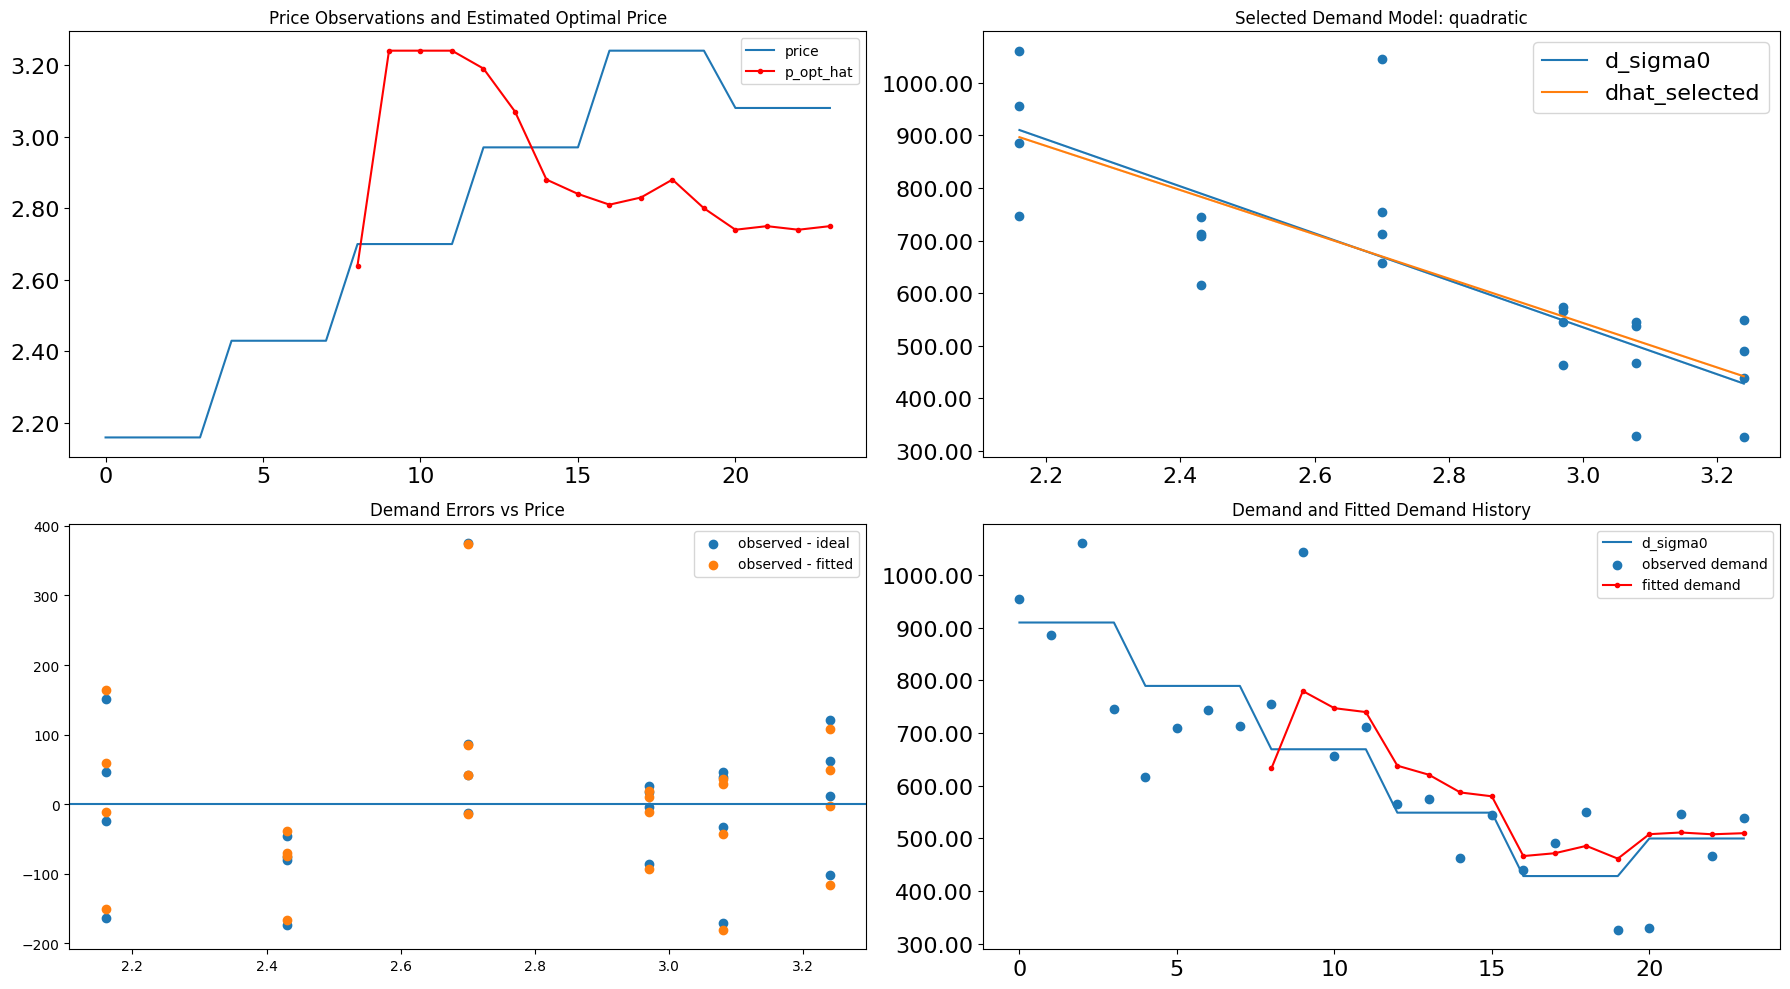

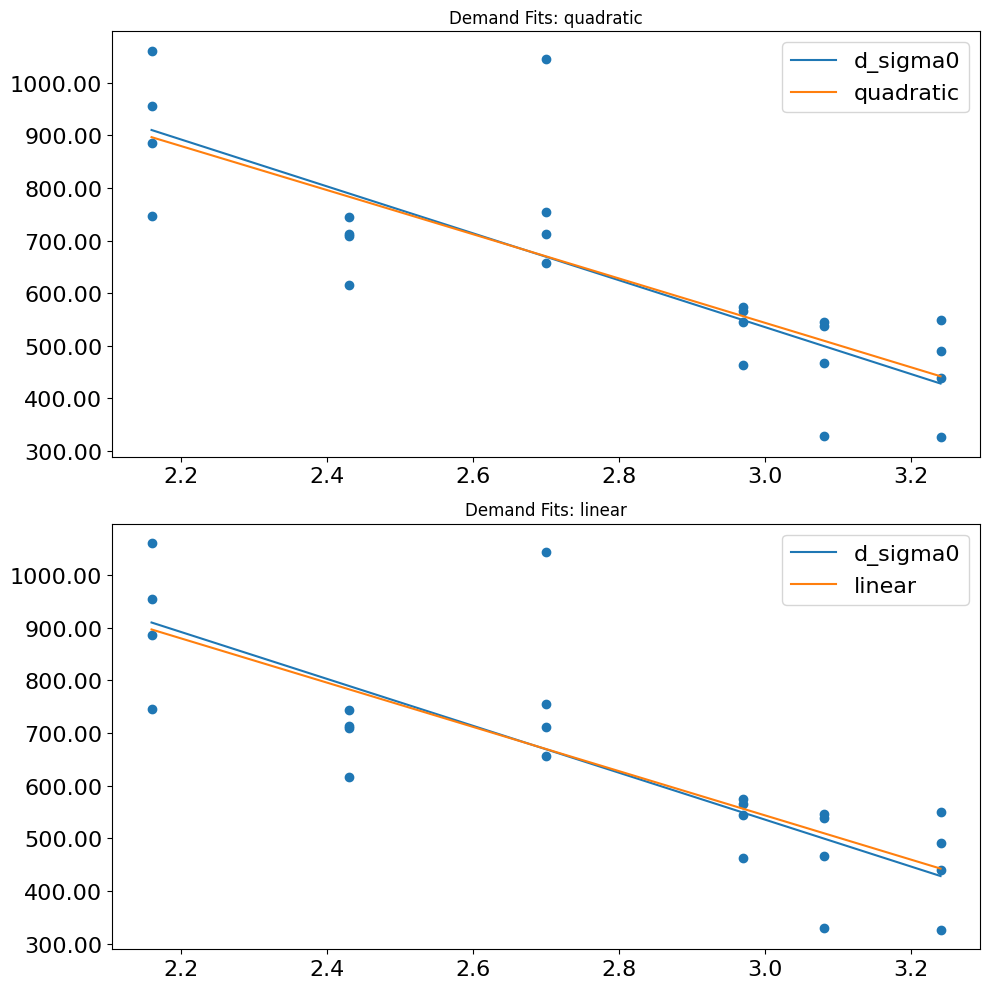


Final model diagnostics:

quadratic:
  AIC = -77.017
  RSS = 0.755038
  p_opt_hat = 2.747
  d_opt_hat = 650.5
  profit_opt_hat = 1000.07
  tilt_error = 20.823587
  tilt_error_low = -36.095773
  tilt_error_high = -15.272186
  is_candidate = True
  p_opt_linear_delta_frac = 0.000000

linear:
  AIC = -79.008
  RSS = 0.755321
  p_opt_hat = 2.747
  d_opt_hat = 650.2
  profit_opt_hat = 999.52
  tilt_error = 20.732650
  tilt_error_low = -36.187307
  tilt_error_high = -15.454657
  tilt_imbalance = 20.732650
  tilt_imbalance =  20.732650
  is_candidate = False
  p_opt_linear_delta_frac = 0.000000


In [143]:
# ========== Evaluate Demand and Price Fits ============#
k = 31 # CHOOSE Experiment K for evaluation
# -------------- extract experiment results -------------

print(f"Experiment k = {k}")
print(f"demand_type = {demand_type}")
print(f"Nloop = {N_loop}, total MAB observations")
if initial_prices:
    print(f"initial_prices = {initial_prices}")
    print(f"N_learn_earn = {N_loop - len(initial_prices)}, Learn and Earn observations")
print(f"N_initial_prices = {N_initial_prices}")
print(f'N_post_init_prices = {N_post_init_prices}')
print(f'Nprice_repeat = {N_price_repeat}')
results_dict_k = results_dict_list[k]

selected_model_type = results_dict_k["selected_model_type"]
model_diagnostics = results_dict_k["model_diagnostics"]
fitted_models = results_dict_k["fitted_models"]

# ------------- Experiment parameters ----------------

print(f"candidate_model_types = {candidate_model_types}")
print(f"default_model_type = {default_model_type}")
print(f"fallback_model_type = {fallback_model_type}")
print(f"models_to_fit = {models_to_fit}")
print(f"tilt_penalty_linear = {tilt_penalty_linear}")
print(f"tilt_penalty_log_log = {tilt_penalty_log_log}")
print(f"tilt_penalty_log_quadratic = {tilt_penalty_log_quadratic}")

print(f"demand_params = {demand_params}")
print(f"sigma_log = {sigma_log}")
print(f"selected_model_type = {selected_model_type}")


# -------------- MAB histories ---------------------

p_history = np.asarray(results_dict_k["p_history"], dtype=float,)
d_history = np.asarray(results_dict_k["d_history"],dtype=float,)
d_sigma0_history = np.asarray( results_dict_k["d_sigma0_history"], dtype=float,)
p_opt_hat_history = np.asarray(  results_dict_k["p_opt_hat_history"], dtype=float,)
d_opt_hat_history = np.asarray(results_dict_k["d_opt_hat_history"], dtype=float,)
d_hat_history = np.asarray( results_dict_k["d_hat_history"], dtype=float,)

print()
print(f"price_history = {p_history.tolist()}")
print()
print(f"demand_history = {d_history.tolist()}")
print()
print(f"d_sigma0_history = {d_sigma0_history.tolist()}")
print()
print(f'p_opt_hat_history = {p_opt_hat_history.tolist()}')
print()
print(f"d_opt_hat_history = {d_opt_hat_history.tolist()}")

# -------------- Fitted demand models -----------------


dhat_models = {
    model_type: fitted_models[model_type]["dhat_model"]
    for model_type in models_to_fit
}

dhat_selected = dhat_models[selected_model_type]


# -------------- Sort observed data by price ------------

sort_idx = np.argsort(p_history)
p_sorted = p_history[sort_idx]
d_sorted = d_history[sort_idx]


# ---------- Demand predictions at observed prices ---------

dhat_selected_sorted = np.asarray(
    dhat_selected(p_sorted),
    dtype=float,
)

# noiseless demand at observed prices
d_sigma0_sorted = np.asarray(  
    get_demand(  demand_type,    demand_params,  p_sorted,sigma_log=0, ), dtype=float,)


# ---------------- Errors -----------------------

# observed demand - ideal noiseless demand
errors_out_of_sample = ( d_sorted - d_sigma0_sorted)

# observed demand - selected fitted demand
errors_residual = ( d_sorted - dhat_selected_sorted)

print()
print(f"errors out-of-sample (observed demand - ideal demand) = {errors_out_of_sample.tolist()}")
print()
print(  f"errors residual  (observed demand - selected fitted demand) = {errors_residual.tolist()}")


# ------------ Price grid --------------------------

p_grid = np.linspace(
    price_min,
    price_max,
    500,
)

d_sigma0_grid = np.asarray(
    get_demand(
        demand_type,
        demand_params,
        p_grid,
        sigma_log=0,
    ),
    dtype=float,
)

# ---------- Fitted-model predictions on price grid ----------

dhat_grid = {}

for model_type in models_to_fit:

    dhat_grid[model_type] = np.asarray(
        dhat_models[model_type](p_grid),
        dtype=float,
    )

# ---------------- Selected-model optimum --------------------

selected_diagnostics = model_diagnostics[
    selected_model_type
]

print()
print(f"selected_model_type = {selected_model_type}")
print(f"p_opt_hat = {selected_diagnostics['p_opt_hat']:.3f}")
print(f"d_opt_hat = {selected_diagnostics['d_opt_hat']:.1f}")
print(f"profit_opt_hat = {selected_diagnostics['profit_opt_hat']:.2f}")


# ----------- Dataframes for plotting --------------

df_observed = pd.DataFrame({
    "price": p_sorted,
    "observed": d_sorted,
    "d_sigma0": d_sigma0_sorted,
    "dhat_selected": dhat_selected_sorted,
    "error_out_of_sample": errors_out_of_sample,
    "error_residual": errors_residual,
})

df_grid = pd.DataFrame({
    "price": p_grid,
    "d_sigma0": d_sigma0_grid,
})

# add each fitted-model prediction
for model_type in models_to_fit:

    df_grid[model_type] = dhat_grid[ model_type]


# ---------- Observation history ----------

df_history = pd.DataFrame({
    "i": np.arange(len(p_history)),
    "price": p_history,
    "demand": d_history,
    "d_sigma0": d_sigma0_history,
})


# ---------- Model-fit history ----------

df_model_history = pd.DataFrame({
    "fit_i": np.arange(len(d_opt_hat_history)),
    "d_opt_hat": d_opt_hat_history,
})


# ==========================================================
# Plot 1: MAB and selected-model diagnostics
# ==========================================================

_fig, axs = plt.subplots( nrows=2,   ncols=2,  figsize=(18, 10),)


# ---------- Price history ----------



bp.lineplot(
    df_history,
    x="i",
    y=["price"],
    ax=axs[0][0],
)

    #  Estimated optimal price history 

axs[0][0].plot(
    np.arange(len(p_opt_hat_history)),
    p_opt_hat_history,
    color="red",
    marker="o",
    markersize=3,
    linewidth=1.5,
    label="p_opt_hat",
)

axs[0][0].legend()

axs[0][0].set_title(
    "Price Observations and Estimated Optimal Price"
)


# ---------- Selected fitted curve vs observed demand ----------

bp.lineplot(
    df_observed,
    x="price",  y=[ "d_sigma0",  "dhat_selected", ],   linestyle="-",  ax=axs[0][1],)

axs[0][1].scatter( p_history,d_history,  marker="o",)

axs[0][1].set_title(
    f"Selected Demand Model: {selected_model_type}"
)


# ---------- Errors vs price ----------

axs[1][0].scatter(
    p_sorted,
    errors_out_of_sample,
    marker="o",
    label="observed - ideal",
)

axs[1][0].scatter(
    p_sorted,
    errors_residual,
    marker="o",
    label="observed - fitted",
)

axs[1][0].axhline(
    y=0,
    linestyle="-",
)

axs[1][0].legend()

axs[1][0].set_title(
    "Demand Errors vs Price"
)


# ---------- Demand history ----------

# noiseless demand for all observations
bp.lineplot(
    df_history,
    x="i",
    y=["d_sigma0"],
    ax=axs[1][1],
)

# observed demand for all observations
axs[1][1].scatter(
    df_history["i"],
    df_history["demand"],
    marker="o",
    label="observed demand",
)

# Fitted demand across all observations
axs[1][1].plot(
    np.arange(len(d_hat_history)),
    d_hat_history,
    color="red",
    marker="o",
    markersize=3,
    linewidth=1.5,
    label="fitted demand",
)

axs[1][1].legend()
axs[1][1].set_title(
    "Demand and Fitted Demand History"
)

plt.tight_layout()
plt.show()


# ==========================================================
# Plot 2: Demand fit for each fitted model
# ==========================================================

N_models = len(models_to_fit)

_fig, axs = plt.subplots(
    nrows=N_models,
    ncols=1,
    figsize=(10, 5 * N_models),
    squeeze=False,
)

axs = axs[:, 0]


for j, model_type in enumerate(
    models_to_fit
):
    ax = axs[j]
    bp.lineplot(  df_grid,
        x="price",   y=[ "d_sigma0",model_type, ],
        linestyle="-", ax=ax )

    ax.scatter(p_history, d_history,  marker="o",)
    ax.set_title(  f"Demand Fits: {model_type}"
    )

plt.tight_layout()
plt.show()


# ==========================================================
# Final model diagnostics
# ==========================================================

print()
print("Final model diagnostics:")

for model_type in models_to_fit:
    diagnostics = model_diagnostics[model_type]

    print()
    print(f"{model_type}:")
    print(f"  AIC = {diagnostics['aic']:.3f}")
    print(f"  RSS = {diagnostics['rss']:.6f}")
    print(f"  p_opt_hat = {diagnostics['p_opt_hat']:.3f}")
    print(f"  d_opt_hat = {diagnostics['d_opt_hat']:.1f}")
    print(
        f"  profit_opt_hat = "
        f"{diagnostics['profit_opt_hat']:.2f}"
    )
    print(f"  tilt_error = {diagnostics['tilt_error']:.6f}")
    print(
        f"  tilt_error_low = "
        f"{diagnostics['tilt_error_low']:.6f}"
    )
    print(
        f"  tilt_error_high = "
        f"{diagnostics['tilt_error_high']:.6f}"
    )

    if model_type == "linear":
        print(
            f"  tilt_imbalance = "
            f"{diagnostics['tilt_imbalance']:.6f}"
        )

    if model_type == "linear":
        print(f"  tilt_imbalance =  {diagnostics['tilt_imbalance']:.6f}")
        
    print(f"  is_candidate = {diagnostics['is_candidate']}")
    print(f"  p_opt_linear_delta_frac = {diagnostics['p_opt_linear_delta_frac']:.6f}")

# Results Summary

All experiments, demand simulations, are configured for p_opt = 2.7

## Logit Demand

**logit demand**  Three model system  
20261010
* p_opt_hat_min ~ 2.5
* p_opt_hat_max ~ 2.92
* Logit demand attempts to simulate realistic demand which changes as prices change. As prices rise consumers are less likely to buy and elasticity (price sensitivity increases). At low prices, consumer buy behavior is less affected by changes prices. 
* After substantial testing a three model system is most effective.
* Candidate model: Log Quadrative Level
* Default Model and Fallback model: Quadtratic with Rigge regularization - Ridge regularization (i.e., L2 regularization) adds a penalty proportional to the sum of the squared coefficients to a model's loss function, thereby keeping the quadratic terms in check - this model has well controled quadratic weights and performs well at the low price end.
* Linear -  genera model fit assessment - curvature and RSS - identifies when the demand variation, relative to a linear fit,  can or cannot be trustted (limited curvature and imbalance)

**logit demand**  Three model system  
20261010

&emsp;   N_experiments = 100  
&emsp;   Nloop = 20, total observations  
&emsp;   Nprice_repeat = 4  
&emsp;   N_initial_prices = 5  
&emsp;   N_post_init_prices = 0

&emsp;   price_min = 2  
&emsp;   price_max = 4.0  

&emsp;   candidate_model_types = ['log_quadratic_level']  
&emsp;   default_model_type = quadratic   
&emsp;   fallback_model_type = linear   
&emsp;   demand_params = {'A': 1338.5518896756485, 'a': 3.6, 'b': 1.3333333333333335}  
&emsp;   boundary_buffer = 0.2  

&emsp;   CV = 0.2  
&emsp;   sigma_lg = 0.19804220043536505  
&emsp;   tilt_penalty_linear = 0  
&emsp;   tilt_penalty_log_quadratic = 0.0  

Statistical summary of p_opt_hat across experiments:  

**Statistical Performance**    
&emsp;   price_min = 2.0  
&emsp;   price_max = 3.6  
&emsp;   ideal p_opt = 2.7  
&emsp;   Let's say max p_opt_hat = 2.95  
&emsp;   and, min p_opt_hat = 2.6  
&emsp;   Approximately we are seeing p_opt_hat = p_opt +/10%  = 2.7 +/-10%
 
**p_opt_hat across experiments:**      
&emsp;   count    100.000000  
&emsp;   mean       2.682300  
&emsp;   std        0.083568  
&emsp;   min        2.510000  
&emsp;   25%        2.620000  
&emsp;   50%        2.675000  
&emsp;   75%        2.720000  
&emsp;   max        2.920000  
Name: p_opt_hat, dtype: float64  

Top 10 experiments by p_opt_hat:
|   k |   p_opt_hat |   p_opt_error | selected_model      |   log_quadratic_level_p_opt_hat |   linear_p_opt_hat |   quadratic_p_opt_hat |
|----:|------------:|--------------:|:--------------------|--------------------------------:|-------------------:|----------------------:|
|  96 |        2.92 |          0.22 | quadratic           |                         2.76152 |            2.9018  |               2.91784 |
|  38 |        2.87 |          0.17 | log_quadratic_level |                         2.86974 |            2.96593 |               2.99399 |
|  49 |        2.85 |          0.15 | log_quadratic_level |                         2.8497  |            2.94589 |               2.96192 |
|  21 |        2.84 |          0.14 | log_quadratic_level |                         2.84168 |            2.93387 |               2.96192 |
|  16 |        2.84 |          0.14 | log_quadratic_level |                         2.83768 |            2.92585 |               2.88577 |
|  24 |        2.84 |          0.14 | log_quadratic_level |                         2.83768 |            2.9499  |               2.95792 |
|  42 |        2.83 |          0.13 | log_quadratic_level |                         2.82565 |            2.92585 |               2.92986 |
|   6 |        2.81 |          0.11 | log_quadratic_level |                         2.80962 |            2.91784 |               2.92986 |
|  95 |        2.8  |          0.1  | log_quadratic_level |                         2.8016  |            2.90982 |               2.90581 |
|  71 |        2.8  |          0.1  | log_quadratic_level |                         2.7976  |            2.89379 |               2.86172 |

...  
Bottom 10 experiments by p_opt_hat:
|   k |   p_opt_hat |   p_opt_error | selected_model      |   log_quadratic_level_p_opt_hat |   linear_p_opt_hat |   quadratic_p_opt_hat |
|----:|------------:|--------------:|:--------------------|--------------------------------:|-------------------:|----------------------:|
|  63 |        2.57 |          0.13 | log_quadratic_level |                         2.57315 |            2.76553 |               2.73747 |
|  27 |        2.57 |          0.13 | log_quadratic_level |                         2.56914 |            2.79359 |               2.77355 |
|  18 |        2.57 |          0.13 | log_quadratic_level |                         2.56914 |            2.75351 |               2.66934 |
|  57 |        2.56 |          0.14 | log_quadratic_level |                         2.55711 |            2.73347 |               2.67735 |
|  31 |        2.55 |          0.15 | log_quadratic_level |                         2.55311 |            2.7495  |               2.70942 |
|  66 |        2.55 |          0.15 | log_quadratic_level |                         2.55311 |            2.75752 |               2.73347 |
|   0 |        2.55 |          0.15 | log_quadratic_level |                         2.5491  |            2.75351 |               2.73347 |
|  78 |        2.54 |          0.16 | log_quadratic_level |                         2.53707 |            2.75752 |               2.73747 |
|  34 |        2.53 |          0.17 | log_quadratic_level |                         2.52505 |            2.75752 |               2.74549 |
|  99 |        2.51 |          0.19 | log_quadratic_level |                         2.50501 |            2.73747 |               2.72144 |

## Linear Demand

### Linear Model 1
20261015
* p_opt_hat_min = 2.5
* p_opt_hat_max = 3.0
* performance with N_price_repeat = 4 and N_initial_prices = 5 (scan from bottom to top), N_loop = 28, is close to that of 2 initial prices with repeat = 16, N_loop = 48 
* In both cases tilt_penalty_linear does not result in consistenly improved performance

**linear demand**  
20261015  
&emsp;   N_experiments = 100  
&emsp;   Nloop = 24, total observations  
&emsp;   Nprice_repeat = 4  
&emsp;   N_initial_prices = 5  
&emsp;   N_post_init_prices = 1 ... 1 x Nprice_repeat = 4

&emsp;   price_min = 2.16  
&emsp;   price_max = 3.24  

&emsp;   candidate_model_types = ['quadratic']  
&emsp;   default_model_type = quadratic  
&emsp;   fallback_model_type = quadratic  
&emsp;   demand_params = {'A': 1873.972645545908, 'b': 0.23809523809523814}  
&emsp;   boundary_buffer = 0.2  

&emsp;   CV = 0.2  
&emsp;   sigma_lg = 0.19804220043536505  
&emsp;   tilt_penalty_linear = 0.0  
&emsp;   tilt_penalty_log_quadratic = 0.0  

&emsp;  price_min = 2.16 ,   price_max = 3.24  
&emsp;  Statistical summary of p_opt_hat across experiments:   
&emsp;  count    100.000000  
&emsp;  mean       2.716400  
&emsp;  std        0.124231  
&emsp;  min        2.500000  
&emsp;  25%        2.627500  
&emsp;  50%        2.710000  
&emsp;  75%        2.810000  
&emsp;  max        3.000000  
Name: p_opt_hat, dtype: float64  

Top 10 experiments by p_opt_hat:
|   k |   p_opt_hat |   p_opt_error | selected_model   |   quadratic_p_opt_hat |   linear_p_opt_hat |
|----:|------------:|--------------:|:-----------------|----------------------:|-------------------:|
|  41 |        3    |          0.3  | quadratic        |               2.99976 |            3.01058 |
|   0 |        2.96 |          0.26 | quadratic        |               2.9608  |            2.94565 |
|  64 |        2.95 |          0.25 | quadratic        |               2.94998 |            2.95214 |
|  25 |        2.95 |          0.25 | quadratic        |               2.95214 |            2.97379 |
|  36 |        2.94 |          0.24 | quadratic        |               2.94349 |            2.94998 |
|  48 |        2.94 |          0.24 | quadratic        |               2.94349 |            2.94349 |
|  20 |        2.92 |          0.22 | quadratic        |               2.91752 |            2.92184 |
|  44 |        2.92 |          0.22 | quadratic        |               2.91968 |            2.92401 |
|  39 |        2.91 |          0.21 | quadratic        |               2.91319 |            2.91535 |
|  49 |        2.9  |          0.2  | quadratic        |               2.89587 |            2.89371 |

Bottom 10 experiments by p_opt_hat:
|   k |   p_opt_hat |   p_opt_error | selected_model   |   quadratic_p_opt_hat |   linear_p_opt_hat |
|----:|------------:|--------------:|:-----------------|----------------------:|-------------------:|
|  55 |        2.55 |          0.15 | quadratic        |               2.55391 |            2.55607 |
|  22 |        2.55 |          0.15 | quadratic        |               2.54525 |            2.54525 |
|   4 |        2.55 |          0.15 | quadratic        |               2.54525 |            2.54309 |
|   1 |        2.54 |          0.16 | quadratic        |               2.54309 |            2.54525 |
|  78 |        2.54 |          0.16 | quadratic        |               2.54092 |            2.54525 |
|  37 |        2.53 |          0.17 | quadratic        |               2.52577 |            2.53226 |
|  89 |        2.52 |          0.18 | quadratic        |               2.51711 |            2.51495 |
|  59 |        2.51 |          0.19 | quadratic        |               2.51495 |            2.52577 |
|  95 |        2.5  |          0.2  | quadratic        |               2.49547 |            2.50196 |
|  90 |        2.5  |          0.2  | quadratic        |               2.4998  |            2.4998  |

### Linear Model 2
20261015 
* This experiment employes only two prices at top and bottom. 
  * Two initial prices repeated 16 times and 1 post initial prices x N_price_repeat = 16 ... total 48
  * With only two initial prices many price repeats are necessary
* Required cranking up N_price_repeat in order to get enough samples for stability
* otherwise, result in boundary violation.
* N_post_initial_prices x N_price_repeat helps pull back into non-boundary violation
* p_opt_hat max 2.96 
* p_opt_hat_min = 2.48
* N_price_repeat = 16
* N_loop = 48

* initial_prices = [3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 2.4, 2.4, 2.4, 2.4, 2.4, 2.4, 2.4, 2.4, 2.4, 2.4, 2.4, 2.4, 2.4, 2.4, 2.4, 2.4]  
* We get some warnings after the initial prices about boundry but the post initial helps to correct
* linear tilt penalty 0 


**linear demand 2**  
20261015  
&emsp;   N_experiments = 100  
&emsp;   Nloop = 48, total observations  
&emsp;   initial_prices = [3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 3.0, 2.4, 2.4, 2.4, 2.4, 2.4, 2.4, 2.4, 2.4, 2.4, 2.4, 2.4, 2.4, 2.4, 2.4, 2.4, 2.4]  
&emsp;   N_learn_earn = 16, Learn and Earn observations  
&emsp;   Nprice_repeat = 16  
&emsp;   N_initial_prices = 5  
&emsp;   N_post_init_prices = 1 ... 1 x Nprice_repeat = 16

&emsp;   price_min = 2.16  
&emsp;   price_max = 3.24  

&emsp;   candidate_model_types = ['linear']  
&emsp;   default_model_type = linear  
&emsp;   fallback_model_type = linear  
&emsp;   demand_params = {'A': 1873.972645545908, 'b': 0.23809523809523814}  
&emsp;   boundary_buffer = 0.2  

&emsp;   CV = 0.2  
&emsp;   sigma_lg = 0.19804220043536505  
&emsp;   tilt_penalty_linear = 0.0  
&emsp;   tilt_penalty_log_quadratic = 0.0  

&emsp;  price_min = 2.16 ,   price_max = 3.24  
Statistical summary of p_opt_hat across experiments:  
count    100.000000
mean       2.698900
std        0.110416
min        2.480000
25%        2.610000
50%        2.710000
75%        2.760000
max        2.960000
Name: p_opt_hat, dtype: float64

Top 10 experiments by p_opt_hat:
|   k |   p_opt_hat |   p_opt_error | selected_model   |   linear_p_opt_hat |
|----:|------------:|--------------:|:-----------------|-------------------:|
|  90 |        2.96 |          0.26 | linear           |            2.95647 |
|  35 |        2.95 |          0.25 | linear           |            2.95214 |
|  78 |        2.93 |          0.23 | linear           |            2.93267 |
|  14 |        2.91 |          0.21 | linear           |            2.90669 |
|  79 |        2.9  |          0.2  | linear           |            2.90236 |
|  29 |        2.89 |          0.19 | linear           |            2.88938 |
|  55 |        2.88 |          0.18 | linear           |            2.87856 |
|  71 |        2.87 |          0.17 | linear           |            2.86774 |
|  24 |        2.87 |          0.17 | linear           |            2.8699  |
|   9 |        2.87 |          0.17 | linear           |            2.87206 |

Bottom 10 experiments by p_opt_hat:
|   k |   p_opt_hat |   p_opt_error | selected_model   |   linear_p_opt_hat |
|----:|------------:|--------------:|:-----------------|-------------------:|
|  60 |        2.54 |          0.16 | linear           |            2.54092 |
|  52 |        2.54 |          0.16 | linear           |            2.54092 |
|  31 |        2.54 |          0.16 | linear           |            2.54092 |
|  70 |        2.53 |          0.17 | linear           |            2.52794 |
|  72 |        2.53 |          0.17 | linear           |            2.5301  |
|  54 |        2.53 |          0.17 | linear           |            2.53226 |
|  67 |        2.53 |          0.17 | linear           |            2.53443 |
|  86 |        2.53 |          0.17 | linear           |            2.52577 |
|  66 |        2.49 |          0.21 | linear           |            2.49331 |
|  97 |        2.48 |          0.22 | linear           |            2.48032 |

## Constant Elasticity

**Constant elasticity demand**  
20261010

* Best performance with 5 initial price scan, just like for the Logit model, through the price range rather than fixed prices on either end (such as with linear demand)
* Need approximately 4 repeats as with logit
* best performing configuration is default and fallback models quadratic - same basic three model configuration as with logit demand.
* included log-log in the candidate models since it theoretically the direct representaion of constant elasticity
* As with Logit model, log-quadratic-level (LQL) model continues to offer a bit better performance at high end quadratic offers a bit better performance on the low end


**Constant Elasticity Eemand**  
20261010   
&emsp;   N_experiments = 100  
&emsp;   Nloop = 24, total observations
&emsp;   Nprice_repeat = 4  
&emsp;   N_initial_prices = 5  
&emsp;   N_post_init_prices = 1

&emsp;   price_min = 2.16  
&emsp;   price_max = 3.24  

&emsp;   candidate_model_types = ['log_quadratic_level', 'log_log']  
&emsp;   default_model_type = quadratic  
&emsp;   fallback_model_type = quadratic  
&emsp;   demand_params = {'A': 4000, 'v': 1.8}  
&emsp;   boundary_buffer = 0.2  

&emsp;   CV = 0.2  
&emsp;   sigma_lg = 0.19804220043536505  
&emsp;   tilt_penalty_linear = 20.0  
&emsp;   tilt_penalty_log_quadratic = 0.0  

&emsp;  price_min = 2.16 ,   price_max = 3.24  
Statistical summary of p_opt_hat across experiments:   
count    100.000000  
mean       2.688600  
std        0.170851  
min        2.380000  
25%        2.550000  
50%        2.665000  
75%        2.800000  
max        3.070000  
Name: p_opt_hat, dtype: float64

Top 10 experiments by p_opt_hat:
|   k |   p_opt_hat |   p_opt_error | selected_model      |   log_quadratic_level_p_opt_hat |   log_log_p_opt_hat |   linear_p_opt_hat |   quadratic_p_opt_hat |
|----:|------------:|--------------:|:--------------------|--------------------------------:|--------------------:|-------------------:|----------------------:|
|  16 |        3.07 |          0.37 | quadratic           |                         3.24    |                3.24 |            3.00192 |               3.07118 |
|  50 |        3.06 |          0.36 | quadratic           |                         3.1123  |                3.24 |            2.96946 |               3.05603 |
|  79 |        3.06 |          0.36 | quadratic           |                         3.24    |                3.24 |            3.05387 |               3.06253 |
|  57 |        3.03 |          0.33 | quadratic           |                         3.14477 |                3.24 |            2.98244 |               3.03439 |
|  12 |        3.01 |          0.31 | quadratic           |                         3.10148 |                3.24 |            3.01707 |               3.01275 |
|  40 |        2.98 |          0.28 | log_quadratic_level |                         2.97595 |                3.24 |            2.82445 |               2.90236 |
|  88 |        2.98 |          0.28 | quadratic           |                         3.24    |                3.24 |            3.05603 |               2.98461 |
|  82 |        2.98 |          0.28 | log_quadratic_level |                         2.98244 |                3.24 |            2.90453 |               2.90236 |
|   7 |        2.97 |          0.27 | quadratic           |                         3.19238 |                3.24 |            3.0279  |               2.97379 |
|  23 |        2.96 |          0.26 | log_quadratic_level |                         2.95864 |                3.24 |            2.94349 |               2.90236 |

Bottom 10 experiments by p_opt_hat:
|   k |   p_opt_hat |   p_opt_error | selected_model      |   log_quadratic_level_p_opt_hat |   log_log_p_opt_hat |   linear_p_opt_hat |   quadratic_p_opt_hat |
|----:|------------:|--------------:|:--------------------|--------------------------------:|--------------------:|-------------------:|----------------------:|
|  28 |        2.48 |          0.22 | log_quadratic_level |                         2.48248 |             2.16    |            2.54958 |               2.54958 |
|  13 |        2.48 |          0.22 | quadratic           |                         2.16    |             2.16    |            2.52144 |               2.48465 |
|  54 |        2.47 |          0.23 | log_log             |                         2.54525 |             2.47166 |            2.65347 |               2.621   |
|  97 |        2.45 |          0.25 | log_quadratic_level |                         2.45218 |             2.42838 |            2.57122 |               2.59936 |
|  34 |        2.44 |          0.26 | log_log             |                         2.57772 |             2.43703 |            2.61234 |               2.61667 |
|  59 |        2.43 |          0.27 | log_log             |                         2.61451 |             2.43271 |            2.67295 |               2.64048 |
|  14 |        2.42 |          0.28 | log_quadratic_level |                         2.41972 |             2.16    |            2.55824 |               2.50413 |
|   8 |        2.39 |          0.31 | log_quadratic_level |                         2.38509 |             2.16    |            2.52361 |               2.47383 |
|  15 |        2.39 |          0.31 | log_log             |                         2.6578  |             2.38725 |            2.62966 |               2.60152 |
|  96 |        2.38 |          0.32 | log_log             |                         2.61234 |             2.38076 |            2.63832 |               2.60152 |





## Generate Documentation

In [144]:
# Generate Experiment Documentation
from IPython.display import Markdown, display

print(f"**{demand_type} demand**  ")
print(f"&emsp;   N_experiments = {N_experiments}  ")
print(f"&emsp;   Nloop = {N_loop}, total observations  ")
if initial_prices:
    print(f"&emsp;   initial_prices = {initial_prices}  ")
    print(f"&emsp;   N_learn_earn = {N_loop - len(initial_prices)}, Learn and Earn observations")
print(f"&emsp;   Nprice_repeat = {N_price_repeat}  ")
print(f"&emsp;   N_initial_prices = {N_initial_prices}  ")
print(f'&emsp;   N_post_init_prices = {N_post_init_prices} x Nprice_repeat = {N_post_init_prices *N_price_repeat}')
print()
print(f"&emsp;   price_min = {price_min}  ")
print(f"&emsp;   price_max = {price_max}  ")
print()
print(f"&emsp;   candidate_model_types = {candidate_model_types}  ")
print(f'&emsp;   default_model_type = {default_model_type}  ')
print(f'&emsp;   fallback_model_type = {fallback_model_type}  ')
print(f"&emsp;   demand_params = {demand_params}  ")
print(f"&emsp;   boundary_buffer = {boundary_buffer}  ")
print()
print(f'&emsp;   CV = {CV}  ')
print(f"&emsp;   sigma_lg = {sigma_lg}  ")
print(f"&emsp;   tilt_penalty_linear = {tilt_penalty_linear}  ")
print(f"&emsp;   tilt_penalty_log_quadratic = {tilt_penalty_log_quadratic}  ")

print()
print(f'&emsp;  price_min = {price_min} ,   price_max = {price_max}  ')
print("Statistical summary of p_opt_hat across experiments:  ")
display( df_experiments["p_opt_hat"].describe())

# ---------- Columns for experiment summaries ----------

cols = [
    "k",
    "p_opt_hat",
    "p_opt_error",
    "selected_model",
]

# Add model-specific p_opt columns only when they exist
model_cols = [
    f"{model_type}_p_opt_hat"
    for model_type in models_to_fit
]

cols.extend(
    col for col in model_cols
    if col in df_experiments.columns
)
print()
print("Top 10 experiments by p_opt_hat:")

print(
    df_experiments[cols]
    .sort_values(
        "p_opt_hat",
        ascending=False,
    )
    .head(10)
    .to_markdown(index=False)
)

print()
print("Bottom 10 experiments by p_opt_hat:")

print(
    df_experiments[cols]
    .nsmallest(10, "p_opt_hat")
    .sort_values("p_opt_hat", ascending=False)
    .to_markdown(index=False)
)


**linear demand**  
&emsp;   N_experiments = 100  
&emsp;   Nloop = 24, total observations  
&emsp;   Nprice_repeat = 4  
&emsp;   N_initial_prices = 5  
&emsp;   N_post_init_prices = 1 x Nprice_repeat = 4

&emsp;   price_min = 2.16  
&emsp;   price_max = 3.24  

&emsp;   candidate_model_types = ['quadratic']  
&emsp;   default_model_type = quadratic  
&emsp;   fallback_model_type = quadratic  
&emsp;   demand_params = {'A': 1873.972645545908, 'b': 0.23809523809523814}  
&emsp;   boundary_buffer = 0.2  

&emsp;   CV = 0.2  
&emsp;   sigma_lg = 0.19804220043536505  
&emsp;   tilt_penalty_linear = 0.0  
&emsp;   tilt_penalty_log_quadratic = 0.0  

&emsp;  price_min = 2.16 ,   price_max = 3.24  
Statistical summary of p_opt_hat across experiments:  


count    100.000000
mean       2.716400
std        0.124231
min        2.500000
25%        2.627500
50%        2.710000
75%        2.810000
max        3.000000
Name: p_opt_hat, dtype: float64


Top 10 experiments by p_opt_hat:
|   k |   p_opt_hat |   p_opt_error | selected_model   |   quadratic_p_opt_hat |   linear_p_opt_hat |
|----:|------------:|--------------:|:-----------------|----------------------:|-------------------:|
|  41 |        3    |          0.3  | quadratic        |               2.99976 |            3.01058 |
|   0 |        2.96 |          0.26 | quadratic        |               2.9608  |            2.94565 |
|  64 |        2.95 |          0.25 | quadratic        |               2.94998 |            2.95214 |
|  25 |        2.95 |          0.25 | quadratic        |               2.95214 |            2.97379 |
|  36 |        2.94 |          0.24 | quadratic        |               2.94349 |            2.94998 |
|  48 |        2.94 |          0.24 | quadratic        |               2.94349 |            2.94349 |
|  20 |        2.92 |          0.22 | quadratic        |               2.91752 |            2.92184 |
|  44 |        2.92 |          0.22 | quadratic 

### Constant Elasticity

N_experiments = 100
N_price_repeat = 4
p_opt_hat max = 2.96
p_opt_hat_max = 
